<a href="https://colab.research.google.com/github/SergeiVKalinin/camm_hackathon/blob/k4my4r/docs/day_23_10232026/Day_22_all_traces_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color = "red">**Deciphering the Decision Logic of an AI Agent**</font>

- Can we infer what an AI agent values by observing the sequence of decisions it makes?

- In this challenge, GPT acts as an autonomous microscopy agent that repeatedly selects one measurement location from a set of candidate AFM image patches.

- We record its decisions and then attempt to reverse-engineer the hidden logic behind those choices using visual, statistical, and data-driven methods.

<font color = "blue" size = 6>**Goal**</font>: develop a method that best explains GPT’s behavior and predicts its future decisions on unseen candidate sets.

<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_20_10092026/llm_decision_making.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and reproducibility

In [1]:
! pip install -q igor2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from igor2 import binarywave
import pickle

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

import random
np.random.seed(42)
import glob
import pickle


Download data

In [3]:
! gdown --folder "https://drive.google.com/drive/folders/1qN-AdhA19oHG3yNo7te7stjzQ_VM1OY_?usp=sharing"

Retrieving folder contents
Processing file 1IgCLQzbzAa0bLQhOvrEErqa1q7qVuDJp eels_ei_trace.pkl
Processing file 1miIUP0M6Yhko255qKCGoswUwqZq0cv7L eels_random_trace.pkl
Processing file 1QpFGNFVC80U2tnFOOaqjEjdTwxI2QWbQ eels_ucb_trace.pkl
Processing file 11qPUBwjyRWKN0DLQgaS2G5Y7lfvk8Rk5 Plasmonic_sets_hackathon.npy
Processing file 1TMwA2uaBMgHbr0FYHrU9SFknZ8Do_HeE trace_P01_eels_.pkl
Processing file 1rSK25XhXesuMGoIsg3kVxKffMchLygSu trace_P03_eels.pkl
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1IgCLQzbzAa0bLQhOvrEErqa1q7qVuDJp
To: /content/day_22/eels_ei_trace.pkl
100% 18.6M/18.6M [00:01<00:00, 9.55MB/s]
Downloading...
From: https://drive.google.com/uc?id=1miIUP0M6Yhko255qKCGoswUwqZq0cv7L
To: /content/day_22/eels_random_trace.pkl
100% 18.6M/18.6M [00:00<00:00, 43.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1QpFGNFVC80U2tnFOOaqjEjdTwxI2QWbQ
To: /content/day_22/e

## load data

In [4]:
fname = "/content/day_22/Plasmonic_sets_hackathon.npy"

raw = np.load(fname, allow_pickle=True)
loadedfile = raw.tolist()

print("Available datasets:", loadedfile.keys())

Available datasets: dict_keys(['0', '1', '2', '3'])


In [5]:
# Use the same dataset as the previous challenge
data = loadedfile["0"]

image = data["image"]
spectra = data["spectrum image"]
energy = data["energy axis"]

H, W, N_E = spectra.shape

print("Image:", image.shape)
print("Spectral image:", spectra.shape)
print("Energy axis:", energy.shape)

Image: (66, 152)
Spectral image: (66, 152, 4198)
Energy axis: (4198,)


## <font color="purple">**2.**</font> Explore the Spectra

Before clustering, always look at the data.

The structural image tells us **where** each spectrum was measured.  
The spectra tell us **what the local EELS response looks like**.

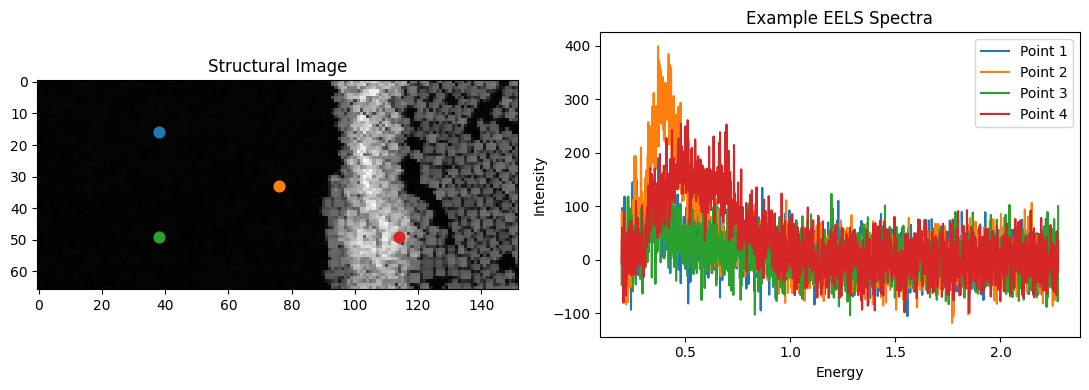

In [6]:
# Pick a few example locations
positions = [
    (H // 4, W // 4),
    (H // 2, W // 2),
    (3 * H // 4, W // 4),
    (3 * H // 4, 3 * W // 4),
]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].imshow(image, cmap="gray")
ax[0].set_title("Structural Image")

for i, (y, x) in enumerate(positions):
    ax[0].scatter(x, y, s=60)
    ax[1].plot(energy, spectra[y, x], label=f"Point {i + 1}")

ax[1].set_title("Example EELS Spectra")
ax[1].set_xlabel("Energy")
ax[1].set_ylabel("Intensity")
ax[1].legend()

plt.tight_layout()
plt.show()

Traces

In [7]:
trace_files = [
    "/content/day_22/eels_ei_trace.pkl",
    "/content/day_22/eels_random_trace.pkl",
    "/content/day_22/eels_ucb_trace.pkl",
    "/content/day_22/trace_P01_eels_.pkl",
    "/content/day_22/trace_P03_eels.pkl"
]

traces = {}

for i, fname in enumerate(trace_files):
    with open(fname, "rb") as f:
        traces[i] = pickle.load(f)

    print(f"Trace {i}: {fname.split('/')[-1]}")

Trace 0: eels_ei_trace.pkl
Trace 1: eels_random_trace.pkl
Trace 2: eels_ucb_trace.pkl
Trace 3: trace_P01_eels_.pkl
Trace 4: trace_P03_eels.pkl


Understanding the EELS Decision Traces
Each trace contains a sequence of decisions made by an agent while exploring an EELS dataset.

At each decision step, the agent is presented with several possible measurement locations and selects one.

For every step, the recorded information may include:
- candidate_positions — spatial coordinates of all available measurement locations.
- selected_position — index of the candidate selected by the agent.
- selected_spectrum — EELS spectrum measured at the selected location.
- selected_axis — corresponding energy-loss axis (eV).
- step — decision step number.
The four traces represent different decision-making strategies: Expected Improvement (EI), Random Sampling, Upper Confidence Bound (UCB), and PO6.

In [8]:
TRACE_ID = 4
STEP = 1

trace = traces[TRACE_ID]
step_data = trace["decisions"][STEP - 1]

print("Step:", step_data["step"])

print("Selected candidate position:", step_data["selected_position"])
print("Selected dataset index:", step_data["selected_index"])
print("Selected coordinates:", step_data["selected_coordinates"])

print("Number of candidates:", len(step_data["candidate_indices"]))
print("Candidate indices:", step_data["candidate_indices"])
print("Candidate coordinates:", step_data["candidate_coordinates"])

# print("Selected reward:", step_data["selected_reward"])

print("Selected spectrum shape:", np.shape(step_data["selected_spectrum"]))
print("Energy axis shape:", np.shape(step_data["selected_axis"]))

Step: 1
Selected candidate position: 10
Selected dataset index: 3926
Selected coordinates: [ 25 126]
Number of candidates: 20
Candidate indices: [ 844 7959 7939 3644 6871 2156 2717 5571 6716 9399 3926 6660 3532  642
 3058 1992 1662 7401 3327 5374]
Candidate coordinates: [[  5  84]
 [ 52  55]
 [ 52  35]
 [ 23 148]
 [ 45  31]
 [ 14  28]
 [ 17 133]
 [ 36  99]
 [ 44  28]
 [ 61 127]
 [ 25 126]
 [ 43 124]
 [ 23  36]
 [  4  34]
 [ 20  18]
 [ 13  16]
 [ 10 142]
 [ 48 105]
 [ 21 135]
 [ 35  54]]
Selected spectrum shape: (4198,)
Energy axis shape: (4198,)


VISUALIZE ONE DECISION STEP

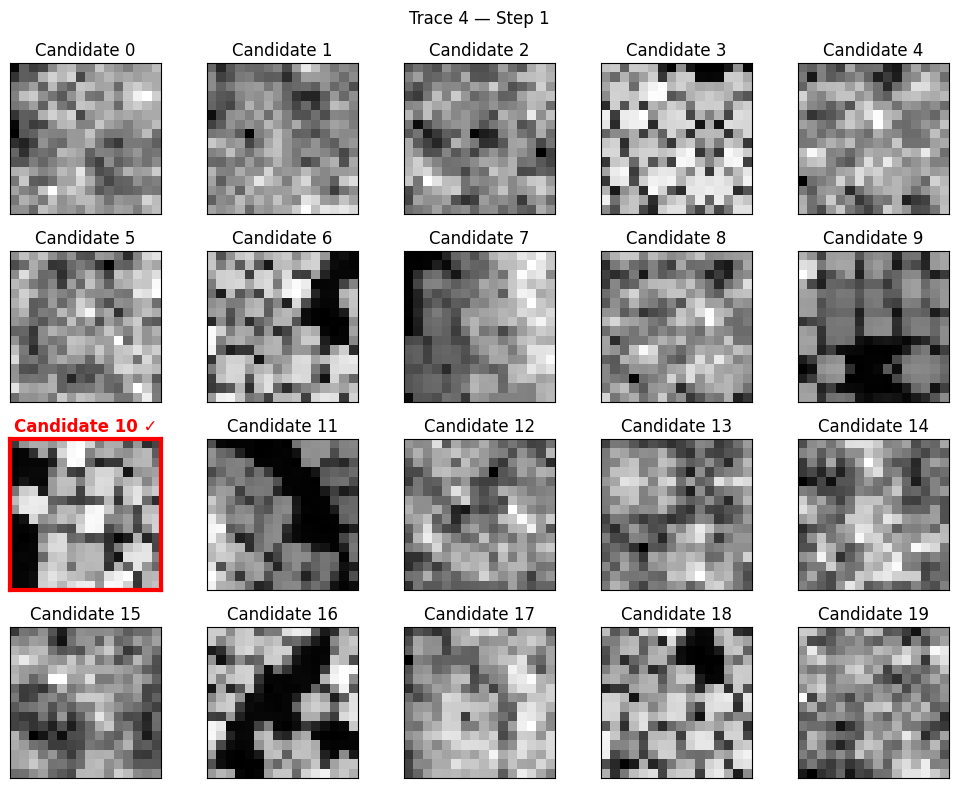

In [9]:
patches = step_data["candidate_patches"]
selected = step_data["selected_position"]

n = len(patches)

ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 2 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i >= n:
        ax.axis("off")
        continue

    patch = np.squeeze(patches[i])   # <-- fixes (1,16,16) -> (16,16)

    ax.imshow(
        patch,
        cmap="gray"
    )

    if i == selected:

        ax.set_title(
            f"Candidate {i} ✓",
            color="red",
            weight="bold"
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(3)

    else:

        ax.set_title(
            f"Candidate {i}"
        )

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    f"Trace {TRACE_ID} — Step {STEP}"
)

plt.tight_layout()
plt.show()

Show the spectrum

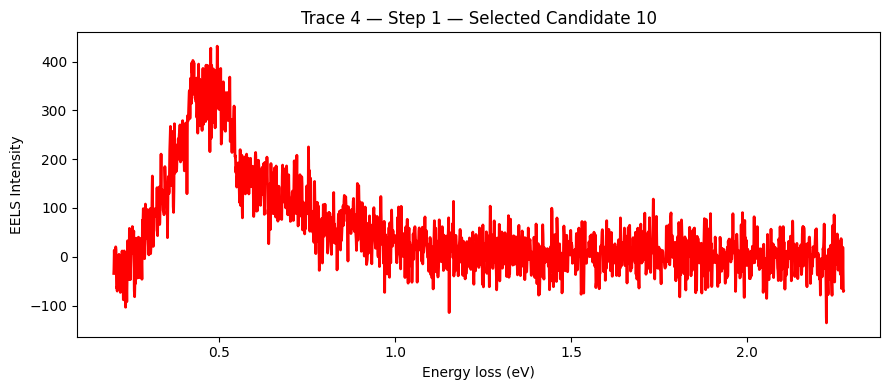

In [10]:
energy = step_data["selected_axis"]
spectrum = step_data["selected_spectrum"]

plt.figure(figsize=(9, 4))

plt.plot(energy, spectrum, color="red", linewidth=2)

plt.xlabel("Energy loss (eV)")
plt.ylabel("EELS Intensity")
plt.title(f"Trace {TRACE_ID} — Step {STEP} — Selected Candidate {selected}")

plt.tight_layout()
plt.show()

TRACE MAP ON ORIGINAL IMAGE

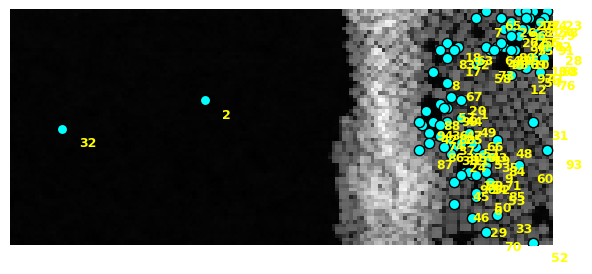

In [11]:
trace = traces[TRACE_ID]
decisions = trace["decisions"]

xs = [d["selected_coordinates"][1] for d in decisions]
ys = [d["selected_coordinates"][0] for d in decisions]

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(image, cmap="gray")

ax.scatter(
    xs, ys,
    s=55,
    color="cyan",
    edgecolors="black"
)

for i, (x, y) in enumerate(zip(xs, ys)):
    ax.text(
        x + 5,
        y + 5,
        str(decisions[i]["step"]),
        fontsize=9,
        color="yellow",
        weight="bold"
    )

ax.axis("off")
plt.show()

DECISION MAPS FOR 10 TRACES


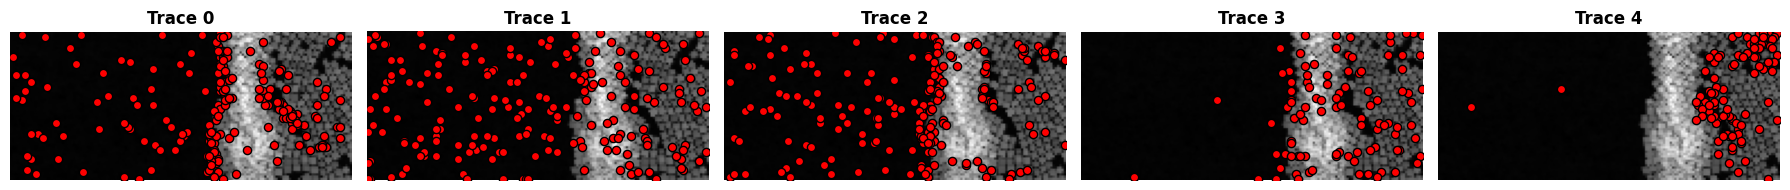

In [12]:
TRACE_IDS = list(traces.keys())

ncols = 5
nrows = int(np.ceil(len(TRACE_IDS) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 5 * nrows)
)

axes = np.array(axes).flatten()

for ax, trace_id in zip(axes, TRACE_IDS):

    trace = traces[trace_id]
    decisions = trace["decisions"]

    xs = [d["selected_coordinates"][1] for d in decisions]
    ys = [d["selected_coordinates"][0] for d in decisions]

    # Original EELS image
    ax.imshow(image, cmap="gray")

    # Selected locations
    ax.scatter(
        xs,
        ys,
        s=35,
        color="red",
        edgecolors="black"
    )

    ax.set_title(
        f"Trace {trace_id}",
        fontsize=12,
        weight="bold"
    )

    ax.axis("off")

# Hide unused axes
for ax in axes[len(TRACE_IDS):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Lightweight Day 22: Visual and spectral-feedback decision models
The **original 24 cells above, including all data-loading cells, are unchanged**. This extension implements five interpretable image features, an optional 4D VAE, three spectral principal components, and only M0/M1/M2. It adds intermediate figures, preference maps, decomposition, temporal snapshots, and a surprise–policy-change diagram. No change-point search, causal model, or bootstrap.

**Models:** M0 uses the current image; M1 adds nearest previously selected image distance; M2 adds predicted spectral PC1 and predicted spectral novelty. All models are conditional-logit choice models, trained to predict which of the 20 candidates is selected. Utility maps are *model-inferred relative preferences*, not physical rewards. The EELS spectra of rejected patches are not used to train decisions.

In [13]:
import os, warnings
from scipy.special import logsumexp, softmax
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from skimage.transform import resize
from scipy.stats import spearmanr
SEED=42
TRACE_TO_ANALYZE=4 # Detailed example; independent all-trace benchmark below
IMAGE_MODE='combined' # 'simple', 'vae', or 'combined'
TRAIN_VAE=True
VAE_EPOCHS=8
MIN_HISTORY=3
L2=1.0
RESULTS='day22_light_results'
os.makedirs(RESULTS,exist_ok=True)
np.random.seed(SEED)

## 1. Validate the trace and inspect image descriptors
Each decision supplies 20 patches, a chosen candidate index, and the observed spectrum. We keep candidate sets intact and preserve temporal order. Five features are computed from 16×16 patches: **raw intensity standard deviation**, **mean normalized gradient magnitude**, **gradient-magnitude standard deviation**, **16-bin intensity entropy**, and **horizontal-versus-vertical gradient anisotropy**. The raw contrast is measured before normalization so it does not become constant. All features are standardized before model fitting. No spatial coordinates enter the decision model.

Trace 0 decisions 200 candidates 20
Trace 1 decisions 200 candidates 20
Trace 2 decisions 200 candidates 20
Trace 3 decisions 100 candidates 20
Trace 4 decisions 100 candidates 20


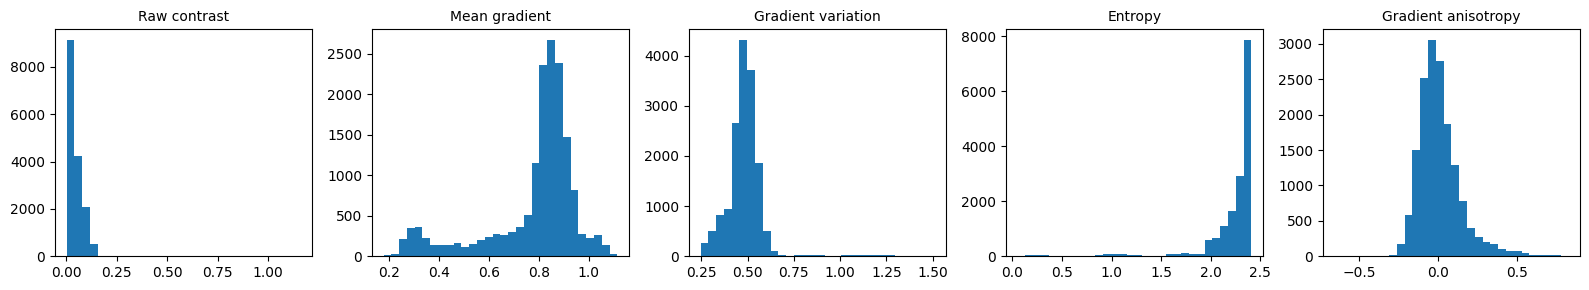

In [14]:
def patch2d(p):
    p=np.asarray(p,dtype=float).squeeze()
    if p.ndim!=2:raise ValueError(f'Invalid patch {p.shape}')
    if p.shape!=(16,16):p=resize(p,(16,16),preserve_range=True,anti_aliasing=True)
    return np.nan_to_num(p)
def feat(p):
    p=patch2d(p); contrast=p.std(); q=(p-p.mean())/(contrast+1e-8)
    gy,gx=np.gradient(q);g=np.hypot(gx,gy)
    h=np.histogram(q,bins=16,range=(-3,3))[0].astype(float);h/=max(h.sum(),1)
    ent=-(h[h>0]*np.log(h[h>0])).sum()
    anis=(np.mean(gx**2)-np.mean(gy**2))/(np.mean(gx**2)+np.mean(gy**2)+1e-9)
    return np.array([contrast,g.mean(),g.std(),ent,anis])
feature_names=['Raw contrast','Mean gradient','Gradient variation','Entropy','Gradient anisotropy']
for tid,tr in traces.items():
    print('Trace',tid,'decisions',len(tr['decisions']),'candidates',len(tr['decisions'][0]['candidate_patches']))
all_patches=[p for tr in traces.values() for d in tr['decisions'] for p in d['candidate_patches']]
F=np.vstack([feat(p) for p in all_patches]);simple_scaler=StandardScaler().fit(F)
fig,ax=plt.subplots(1,5,figsize=(16,3))
for i,a in enumerate(ax):a.hist(F[:,i],bins=30);a.set_title(feature_names[i],fontsize=10)
plt.tight_layout();plt.show()

## 2. Optional four-dimensional VAE
The VAE is a small, fully connected image autoencoder with encoder 256→64→32→4 and a symmetric decoder. It learns from **images only**, using reconstruction MSE plus 0.01×KL regularization. We visualize its training loss and sample reconstructions. The deterministic encoder mean becomes the four-dimensional descriptor. The default **combined** representation concatenates five standardized simple features with four standardized VAE latents (nine dimensions). Set `IMAGE_MODE='simple'` and `TRAIN_VAE=False` for a faster CPU-only run.

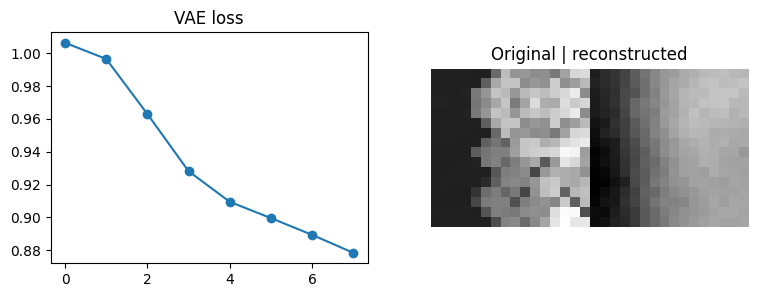

In [15]:
vae=None
if TRAIN_VAE:
    try:
        import torch
        from torch import nn
        torch.manual_seed(SEED)
        class VAE(nn.Module):
            def __init__(self):
                super().__init__();self.enc=nn.Sequential(nn.Linear(256,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU())
                self.mu=nn.Linear(32,4);self.lv=nn.Linear(32,4)
                self.dec=nn.Sequential(nn.Linear(4,32),nn.ReLU(),nn.Linear(32,64),nn.ReLU(),nn.Linear(64,256))
            def encode(self,x):
                h=self.enc(x);return self.mu(h),self.lv(h)
            def forward(self,x):
                mu,lv=self.encode(x);z=mu+torch.randn_like(mu)*torch.exp(.5*lv)
                return self.dec(z),mu,lv
        vae=VAE();opt=torch.optim.Adam(vae.parameters(),lr=.001)
        rng=np.random.default_rng(SEED);ids=rng.choice(len(all_patches),min(5000,len(all_patches)),replace=False)
        a=np.stack([patch2d(all_patches[i]) for i in ids]);a=(a-a.mean((1,2),keepdims=True))/(a.std((1,2),keepdims=True)+1e-8)
        x=torch.tensor(a.reshape(-1,256),dtype=torch.float32)
        losses=[]
        for ep in range(VAE_EPOCHS):
            order=torch.randperm(len(x));running=0
            for batch in order.split(256):
                v=x[batch];rec,mu,lv=vae(v);loss=((rec-v)**2).mean()+.01*(-.5*(1+lv-mu**2-lv.exp()).sum(1)).mean()
                opt.zero_grad();loss.backward();opt.step();running+=loss.item()*len(batch)
            losses.append(running/len(x))
        vae.eval()
        fig,axs=plt.subplots(1,2,figsize=(9,3));axs[0].plot(losses,'o-');axs[0].set_title('VAE loss')
        with torch.no_grad():rec=vae(x[:1])[0].numpy().reshape(16,16)
        axs[1].imshow(np.concatenate([a[0],rec],axis=1),cmap='gray');axs[1].set_title('Original | reconstructed');axs[1].axis('off');plt.show()
    except ImportError:
        warnings.warn('PyTorch not installed; using simple features');vae=None;IMAGE_MODE='simple'
def vae_encode(patches):
    if vae is None:raise RuntimeError('VAE not trained')
    out=[]
    with torch.no_grad():
        for j in range(0,len(patches),512):
            a=np.stack([patch2d(p) for p in patches[j:j+512]])
            a=(a-a.mean((1,2),keepdims=True))/(a.std((1,2),keepdims=True)+1e-8)
            out.append(vae.encode(torch.tensor(a.reshape(-1,256),dtype=torch.float32))[0].numpy())
    return np.vstack(out)
if IMAGE_MODE!='simple' and vae is None:raise RuntimeError('Enable TRAIN_VAE or select simple mode')
vae_scaler=StandardScaler().fit(vae_encode(all_patches)) if IMAGE_MODE!='simple' else None
def encode(patches):
    f=simple_scaler.transform(np.vstack([feat(p) for p in patches]))
    if IMAGE_MODE=='simple':return f
    z=vae_scaler.transform(vae_encode(patches))
    return z if IMAGE_MODE=='vae' else np.column_stack([f,z])

## 3. Three spectral principal components
Spectra are downsampled to at most 256 energy channels. A channel-wise scaler and PCA are fitted on **other traces**, not the trace currently being explained. This gives a fixed three-component spectral representation without using future observations from the target trace to define its basis. We display explained variance and PCA loadings. PC1 is a statistical coordinate, **not automatically spectral amplitude**.

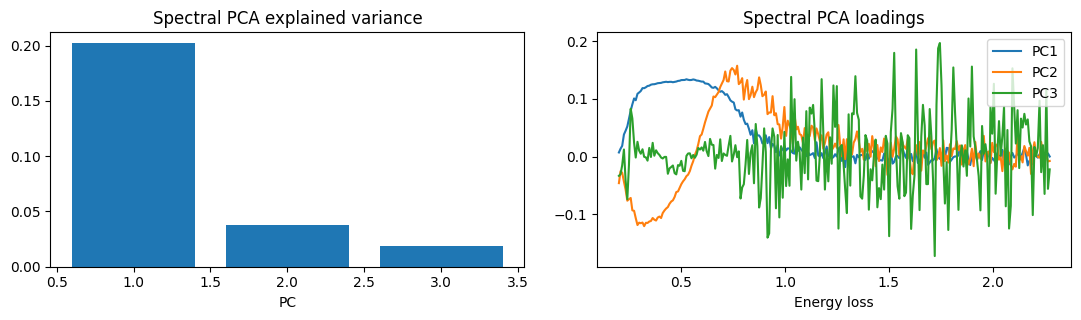

In [16]:
train_spectra=[np.asarray(d['selected_spectrum'],float).ravel() for tid,tr in traces.items() if tid!=TRACE_TO_ANALYZE for d in tr['decisions']]
if not train_spectra:raise ValueError('Need another trace for PCA basis')
n=min(map(len,train_spectra));channels=np.unique(np.linspace(0,n-1,min(256,n)).astype(int))
Y=np.stack([np.nan_to_num(y[channels]) for y in train_spectra]);yscaler=StandardScaler().fit(Y)
pca=PCA(n_components=min(3,len(Y),Y.shape[1]),random_state=SEED).fit(yscaler.transform(Y))
def ypc(y):return pca.transform(yscaler.transform(np.nan_to_num(np.asarray(y,float).ravel()[channels]).reshape(1,-1)))[0]
fig,ax=plt.subplots(1,2,figsize=(11,3.3));ax[0].bar(np.arange(pca.n_components_)+1,pca.explained_variance_ratio_)
ax[0].set_title('Spectral PCA explained variance');ax[0].set_xlabel('PC')
for j,pc in enumerate(pca.components_):ax[1].plot(np.asarray(energy).ravel()[channels],pc,label=f'PC{j+1}')
ax[1].set_title('Spectral PCA loadings');ax[1].set_xlabel('Energy loss');ax[1].legend();plt.tight_layout();plt.show()

## 4. Chronological features and three choice models
**M0** uses image features only. **M1** adds the minimum Euclidean distance from the candidate image descriptor to any previously selected image descriptor. **M2** adds (i) predicted spectral PC1 and (ii) predicted spectral novelty (distance from predicted three-PC spectrum to previously observed three-PC spectra). The spectral predictor is ridge regression with regularization 10, refitted from *past selected measurements only* at each step. It activates after three measurements.

The decision likelihood is \(P(a_t=i)=\mathrm{softmax}_i(w^T\phi_{t,i})\). We fit L2-regularized weights by vectorized negative log-likelihood. Feature scaling is fitted on the target trace's candidate features for descriptive modeling; a separate held-out trace evaluation is optional. We cache chronological features so later plotting is fast.

,model,train_logp,test_logp,test_top1
0,M0 visual,-1.722363,-1.762336,0.400000
1,M1 + image history,-1.501711,-1.300677,0.500000
2,M2 + spectral history,-1.473638,-1.341327,0.533333


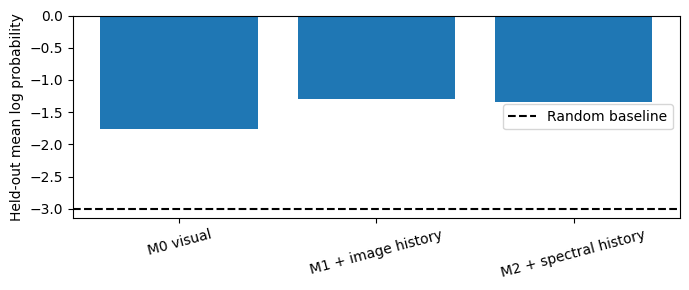

Note: M2 vs M1 is the primary comparison. PCA basis comes from other traces.


In [17]:
trace=traces[TRACE_TO_ANALYZE]['decisions']
Xsets=[encode(d['candidate_patches']) for d in trace]
Yselected=[ypc(d['selected_spectrum']) for d in trace]
chosen=[int(d['selected_position']) for d in trace]
if len(set(map(len,Xsets)))!=1:raise ValueError('Choice-set sizes vary; this lightweight version expects equal candidate counts')
N=len(trace);K=len(Xsets[0]);dx=Xsets[0].shape[1]
# Build the three feature tensors in one chronological pass.
blocks=[];pastx=[];pasty=[]
for t,(x,y,a) in enumerate(zip(Xsets,Yselected,chosen)):
    novelty=np.min(np.linalg.norm(x[:,None,:]-np.array(pastx)[None,:,:],axis=2),axis=1) if pastx else np.zeros(K)
    sf=np.zeros((K,2))
    if len(pastx)>=3:
        pred=Ridge(alpha=10).fit(np.array(pastx),np.array(pasty)).predict(x)
        sf[:,0]=pred[:,0]
        sf[:,1]=np.min(np.linalg.norm(pred[:,None,:]-np.array(pasty)[None,:,:],axis=2),axis=1)
    blocks.append((x,novelty[:,None],sf))
    pastx.append(x[a]);pasty.append(y)
# One common standardization per feature block, across candidate rows.
raw=np.stack([np.column_stack(b) for b in blocks])
scaler=StandardScaler().fit(raw.reshape(-1,dx+3))
scaled=scaler.transform(raw.reshape(-1,dx+3)).reshape(N,K,dx+3)
X0=scaled[:,:,:dx];X1=scaled[:,:,:dx+1];X2=scaled
choice=np.array(chosen,dtype=int)
def fit_choice(X,indices=None):
    if indices is None:indices=np.arange(len(X))
    z=X[indices];a=choice[indices];T=len(z);d=z.shape[-1]
    def loss(w):
        u=z@w;prob=softmax(u,axis=1)
        val=(logsumexp(u,axis=1)-u[np.arange(T),a]).sum()+.5*L2*(w@w)
        grad=(prob[:,:,None]*z).sum(axis=(0,1))-z[np.arange(T),a].sum(axis=0)+L2*w
        return val,grad
    return minimize(loss,np.zeros(d),jac=True,method='L-BFGS-B').x
def metrics(X,w,indices):
    u=X[indices]@w;logp=u-logsumexp(u,axis=1,keepdims=True);a=choice[indices]
    return [np.mean(logp[np.arange(len(indices)),a]),np.mean(np.argmax(u,axis=1)==a)]
# Chronological holdout within the selected trace. Spectral predictor always uses only past observations.
split=max(3,int(.7*N));train=np.arange(split);test=np.arange(split,N)
weights=[fit_choice(X,train) for X in (X0,X1,X2)]
results=pd.DataFrame([{'model':name,'train_logp':metrics(X,w,train)[0],
 'test_logp':metrics(X,w,test)[0] if len(test) else np.nan,
 'test_top1':metrics(X,w,test)[1] if len(test) else np.nan}
 for name,X,w in zip(['M0 visual','M1 + image history','M2 + spectral history'],[X0,X1,X2],weights)])
display(results)
fig,ax=plt.subplots(figsize=(7,3));ax.bar(results.model,results.test_logp);ax.axhline(-np.log(K),ls='--',c='black',label='Random baseline');ax.tick_params(axis='x',rotation=15);ax.set_ylabel('Held-out mean log probability');ax.legend();plt.tight_layout();plt.show()
print('Note: M2 vs M1 is the primary comparison. PCA basis comes from other traces.')

## 5. Full-grid preference maps and intermediate descriptor maps
We extract a 16×16 image patch at every grid pixel using reflect padding, then apply the **same fitted image encoders**. We display the five simple descriptor maps as a diagnostic. Because the source candidate patches may use a different extraction convention, compare a few reconstructed patches against recorded candidates before treating the utility maps as spatially exact.

The full-grid maps use the fitted weights from the **training portion** of the selected trace. At each snapshot, only images and spectra already observed before that time are used to build history features. Utilities are centered across the grid for visualization. They are not probabilities; the actual choices were made among 20 candidates, not all grid pixels.

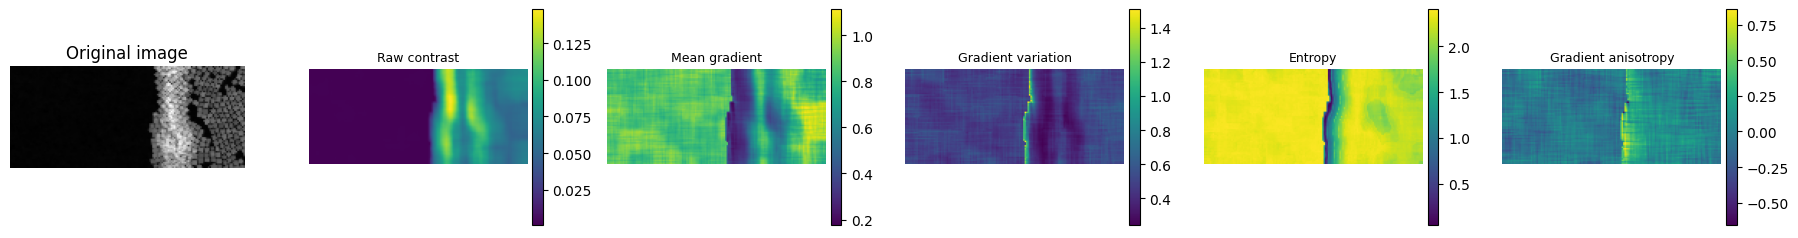

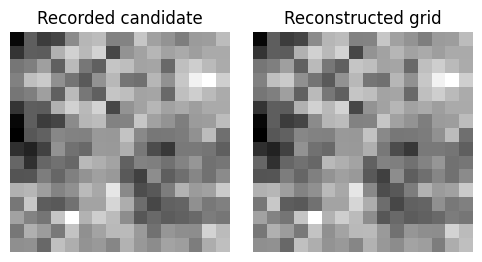

In [18]:
base=np.asarray(image,float).squeeze()
if base.shape!=(H,W):
    print('Structural image shape:',base.shape,'spectral grid:',(H,W))
    if base.size==H*W:base=base.reshape(H,W)
    else:raise ValueError('Structural image grid does not match spectra grid')
padded=np.pad(base,((8,8),(8,8)),mode='reflect')
grid_patches=[padded[r:r+16,c:c+16] for r in range(H) for c in range(W)]
rawgrid=np.vstack([feat(p) for p in grid_patches]);grid_x=encode(grid_patches)
fig,ax=plt.subplots(1,6,figsize=(18,3))
ax[0].imshow(base,cmap='gray');ax[0].set_title('Original image')
for j in range(5):
    im=ax[j+1].imshow(rawgrid[:,j].reshape(H,W),cmap='viridis');ax[j+1].set_title(feature_names[j],fontsize=9)
    plt.colorbar(im,ax=ax[j+1],fraction=.046,pad=.02)
for a in ax:a.axis('off')
plt.tight_layout();plt.savefig(os.path.join(RESULTS,'descriptor_maps.png'),dpi=150);plt.show()
# Audit patch convention using one recorded candidate with a known coordinate.
d=trace[0]
if 'candidate_coordinates' in d:
    coords=np.asarray(d['candidate_coordinates'])
    if coords.ndim==2 and coords.shape[1]>=2:
        r,c=map(int,coords[0,:2]);
        if 0<=r<H and 0<=c<W:
            fig,ax=plt.subplots(1,2,figsize=(5,2.6))
            ax[0].imshow(patch2d(d['candidate_patches'][0]),cmap='gray');ax[0].set_title('Recorded candidate')
            ax[1].imshow(grid_patches[r*W+c],cmap='gray');ax[1].set_title('Reconstructed grid')
            for a in ax:a.axis('off')
            plt.tight_layout();plt.show()

## 6. Utility maps: M0, M1, M2, and additive M2 decomposition
We evaluate each model on the same reference grid at five experimental checkpoints. **M0** is static. **M1** evolves when selected image descriptors are added. **M2** evolves when selected images and spectra are added.

Within M2 the decomposition is exact: visual term + image-history term + spectral-history terms = M2 total. The **M2−M1** difference is also displayed, but it includes changes in coefficients from fitting different models; it should not be called a pure spectral effect. The spectral component *inside M2* is the cleaner additive attribution. Maps are centered for comparison, and difference maps use symmetric color scales.

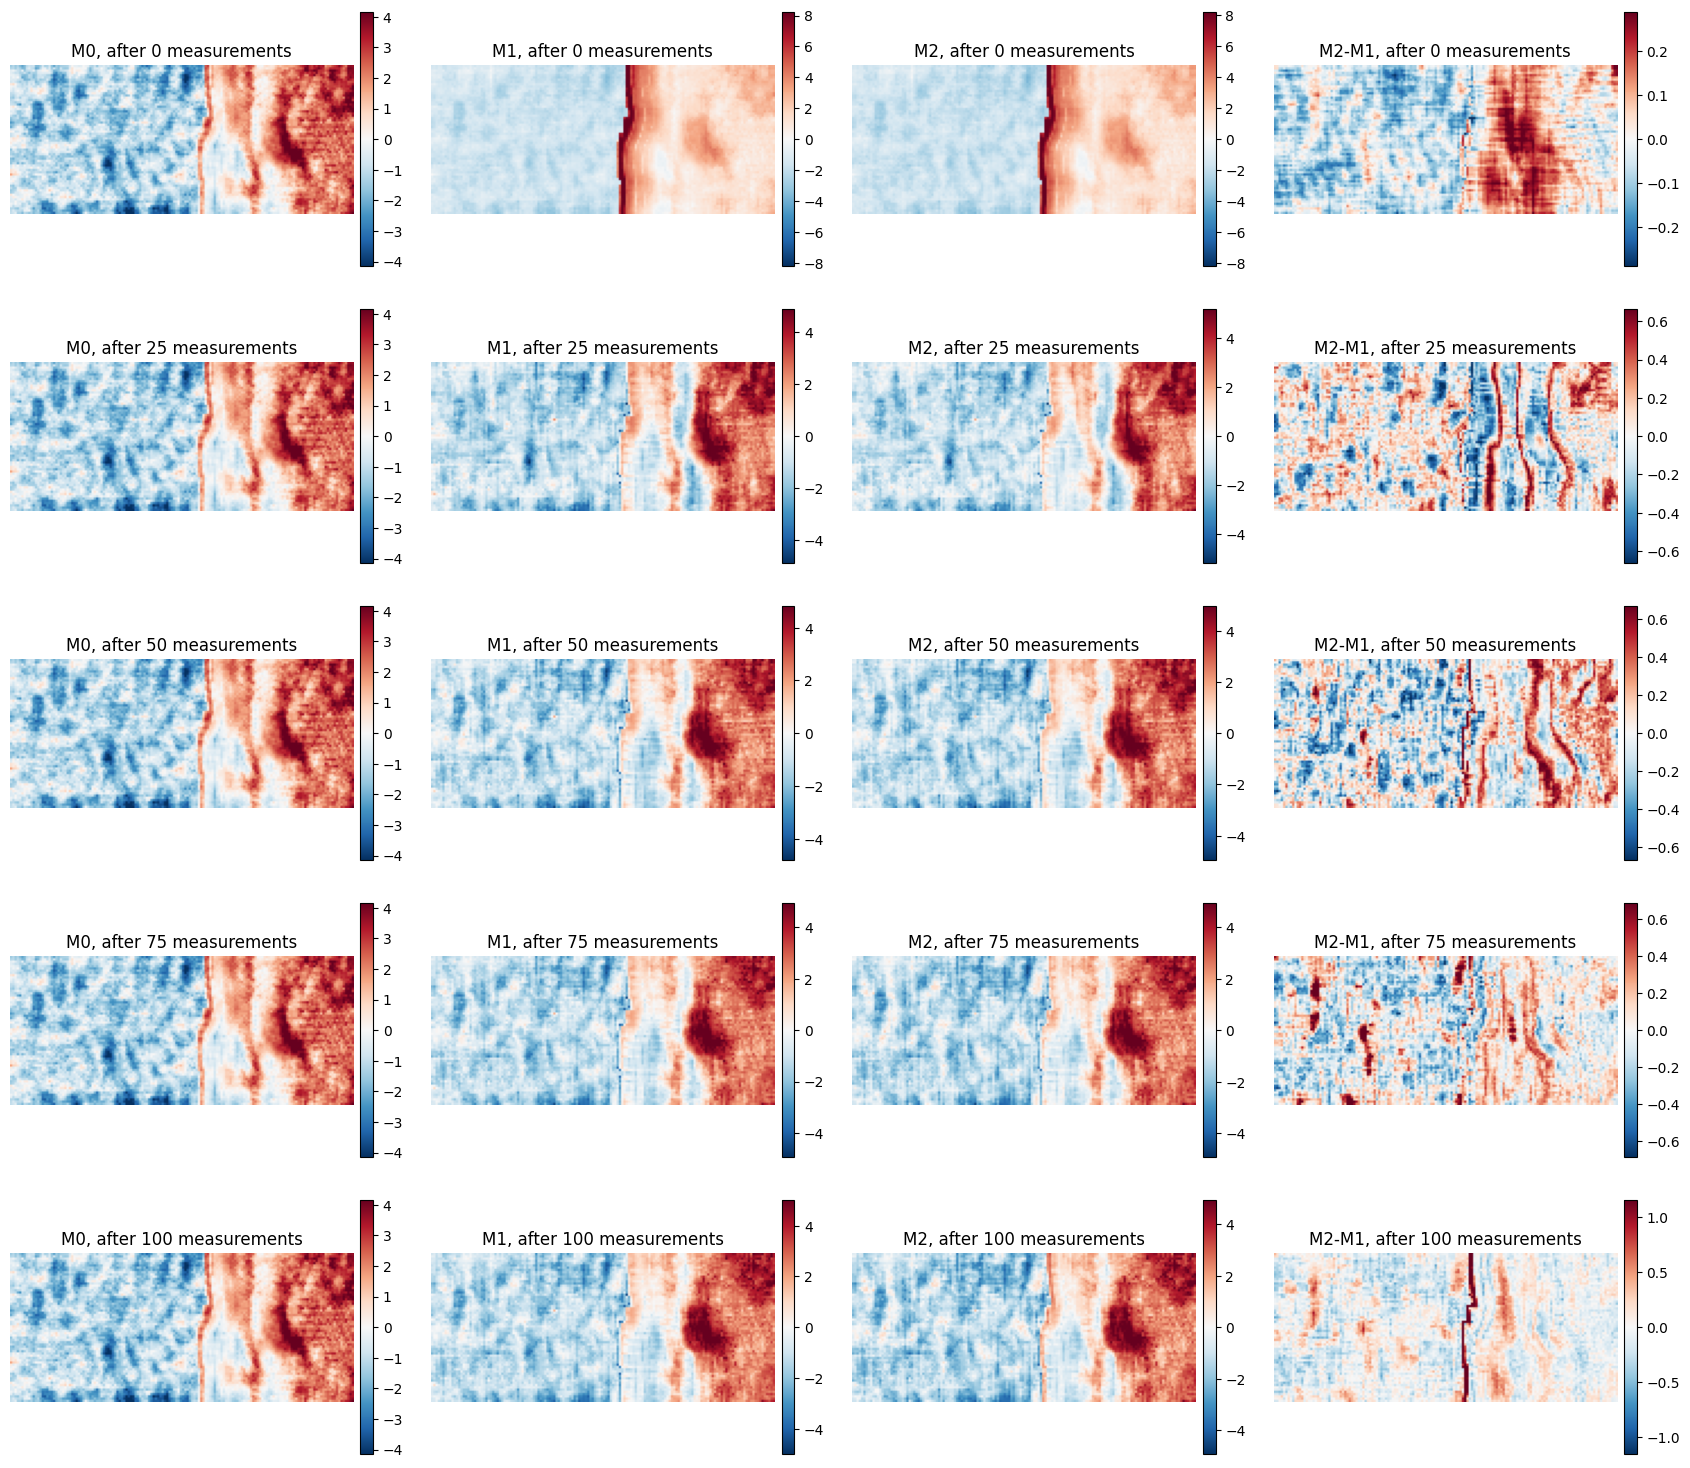

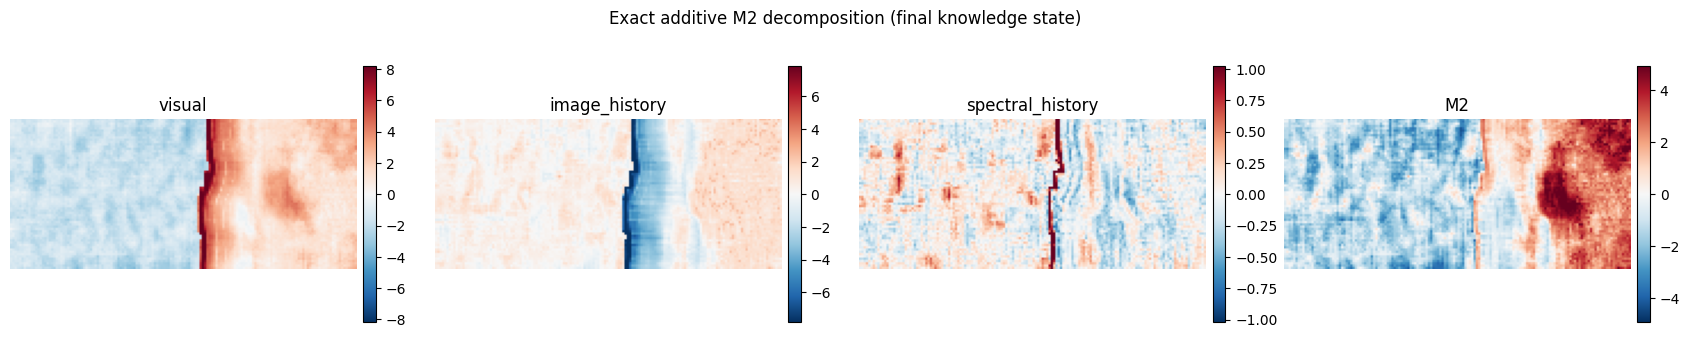

In [19]:
def grid_features(t,with_spectrum=True):
    # t = number of completed measurements, so history includes steps [0,t).
    t=max(0,min(int(t),N))
    novelty=np.zeros(len(grid_x));sp=np.zeros((len(grid_x),2))
    if t:
        hx=np.stack([Xsets[j][chosen[j]] for j in range(t)])
        # Chunk distance calculation to avoid allocating (10032 x T x d) at once.
        for start in range(0,len(grid_x),512):
            q=grid_x[start:start+512]
            novelty[start:start+512]=np.min(np.linalg.norm(q[:,None,:]-hx[None,:,:],axis=2),axis=1)
        if with_spectrum and t>=MIN_HISTORY:
            hy=np.stack(Yselected[:t]);pred=Ridge(alpha=10).fit(hx,hy).predict(grid_x)
            sp[:,0]=pred[:,0]
            for start in range(0,len(grid_x),512):
                q=pred[start:start+512]
                sp[start:start+512,1]=np.min(np.linalg.norm(q[:,None,:]-hy[None,:,:],axis=2),axis=1)
    z=np.column_stack([grid_x,novelty,sp])
    return scaler.transform(z)

def maps_at(t):
    z=grid_features(t)
    v0=z[:,:dx]@weights[0]
    v1=z[:,:dx+1]@weights[1]
    visual=z[:,:dx]@weights[2][:dx]
    history=z[:,dx]*weights[2][dx]
    spectral=z[:,dx+1:]@weights[2][dx+1:]
    v2=visual+history+spectral
    return {key:val.reshape(H,W) for key,val in {
        'M0':v0,'M1':v1,'M2':v2,'M2-M1':v2-v1,
        'visual':visual,'image_history':history,'spectral_history':spectral}.items()}

checkpoints=sorted(set([int(round(f*N)) for f in [0,.25,.5,.75,1]]))
cache={t:maps_at(t) for t in checkpoints}
fig,axes=plt.subplots(len(checkpoints),4,figsize=(17,3.0*len(checkpoints)),squeeze=False)
for row,t in enumerate(checkpoints):
    maps=cache[t]
    for col,key in enumerate(['M0','M1','M2','M2-M1']):
        z=maps[key]-maps[key].mean();lim=max(np.percentile(np.abs(z),99),1e-8)
        im=axes[row,col].imshow(z,cmap='RdBu_r',vmin=-lim,vmax=lim)
        axes[row,col].set_title(f'{key}, after {t} measurements');axes[row,col].axis('off')
        fig.colorbar(im,ax=axes[row,col],fraction=.035,pad=.02)
plt.tight_layout();plt.savefig(os.path.join(RESULTS,'utility_atlas.png'),dpi=150);plt.show()

last=cache[checkpoints[-1]]
fig,axes=plt.subplots(1,4,figsize=(17,3.5))
for a,key in zip(axes,['visual','image_history','spectral_history','M2']):
    z=last[key]-last[key].mean();lim=max(np.percentile(np.abs(z),99),1e-8)
    im=a.imshow(z,cmap='RdBu_r',vmin=-lim,vmax=lim);a.set_title(key);a.axis('off')
    fig.colorbar(im,ax=a,fraction=.035,pad=.02)
plt.suptitle('Exact additive M2 decomposition (final knowledge state)');plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'m2_decomposition.png'),dpi=150);plt.show()
assert np.allclose(last['visual']+last['image_history']+last['spectral_history'],last['M2'])

## 7. Spectral surprise versus policy change
At step \(t\), a ridge predictor is trained only on the **previously selected** image/spectrum pairs. Spectral surprise is the Euclidean distance in three-PC space between its prediction and the newly observed spectrum. Because ridge regression is not probabilistic, this is a **prediction error**, not a calibrated negative log-likelihood.

For each observed spectrum, we evaluate the M2 policy on a **fixed reference choice set** (the first recorded set of 20 patches) immediately before and after updating the history. Policy change is KL divergence between these two probability vectors. The current diagnostic captures the **combined image-history and spectral-history update**. It does not isolate the spectral-only effect; the M2-versus-M1 predictive comparison is the primary control for image history. This is a model-based diagnostic, not a causal estimate of the human's response.

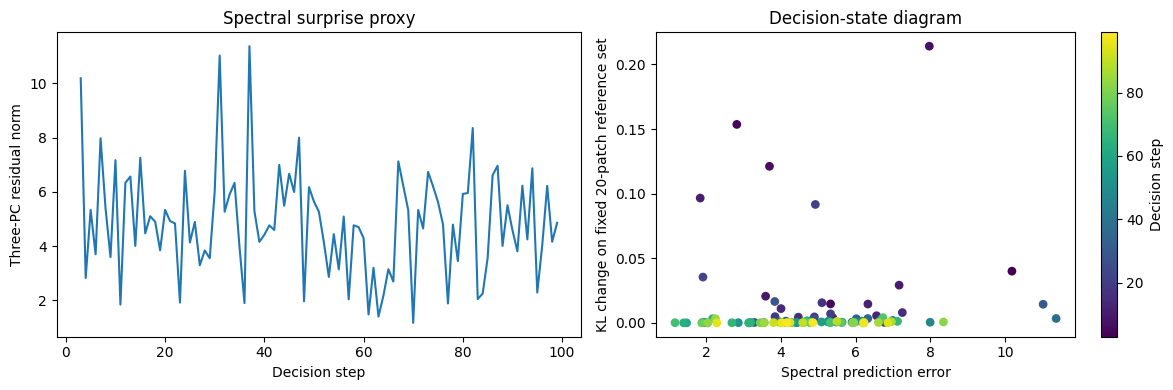

Spearman correlation (descriptive): SignificanceResult(statistic=np.float64(0.3328292657269093), pvalue=np.float64(0.0008653584745247049))


In [20]:
reference=Xsets[0]
def ref_policy(t,extra_image=None,extra_spectrum=None):
    # t completed observed steps; optional extra measurement for a controlled model update.
    hx=[Xsets[j][chosen[j]] for j in range(t)]
    hy=[Yselected[j] for j in range(t)]
    if extra_image is not None:hx.append(extra_image)
    if extra_spectrum is not None:hy.append(extra_spectrum)
    if len(hx)!=len(hy):
        # Spectral-only comparison holds the image-history novelty fixed at t,
        # but fits the spectral predictor using the new (image,spectrum) pair.
        raise ValueError('History length mismatch')
    novel=np.min(np.linalg.norm(reference[:,None,:]-np.array(hx)[None,:,:],axis=2),axis=1) if hx else np.zeros(K)
    s=np.zeros((K,2))
    if len(hx)>=MIN_HISTORY:
        pred=Ridge(alpha=10).fit(np.array(hx),np.array(hy)).predict(reference)
        s[:,0]=pred[:,0]
        s[:,1]=np.min(np.linalg.norm(pred[:,None,:]-np.array(hy)[None,:,:],axis=2),axis=1)
    z=scaler.transform(np.column_stack([reference,novel,s]))
    return softmax(z@weights[2])

surprises=[];changes=[];times=[]
for t in range(MIN_HISTORY,N):
    hx=np.stack([Xsets[j][chosen[j]] for j in range(t)])
    hy=np.stack(Yselected[:t])
    pred=Ridge(alpha=10).fit(hx,hy).predict(Xsets[t][chosen[t]:chosen[t]+1])[0]
    surprises.append(np.linalg.norm(pred-Yselected[t]))
    before=ref_policy(t);after=ref_policy(t+1)
    changes.append(np.sum(after*np.log((after+1e-12)/(before+1e-12))))
    times.append(t)
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(times,surprises,label='Spectral prediction error');axs[0].set(xlabel='Decision step',ylabel='Three-PC residual norm',title='Spectral surprise proxy')
sc=axs[1].scatter(surprises,changes,c=times,cmap='viridis',s=28)
axs[1].set(xlabel='Spectral prediction error',ylabel='KL change on fixed 20-patch reference set',title='Decision-state diagram')
fig.colorbar(sc,ax=axs[1],label='Decision step');plt.tight_layout()
plt.savefig(os.path.join(RESULTS,'surprise_policy_change.png'),dpi=150);plt.show()
if len(surprises)>3:
    print('Spearman correlation (descriptive):',spearmanr(surprises,changes))

## 8. Interpretation and limitations
**What the outputs can establish:** (1) whether current image descriptors predict selected candidates; (2) whether previously selected image morphologies add predictive power; (3) whether previous spectral observations improve held-out choice prediction; and (4) where and how the fitted preference landscape changes in the reconstructed model.

**What they cannot establish:** The human's true psychological reward function, causality of spectral feedback, or superiority of a policy on scientific outcomes. Spectral PCs are not automatically physical mechanisms. The spectral prediction error and policy-change scatter are descriptive. The same images occur across traces, so performance on a later portion of one trace does not demonstrate transfer to new specimens. Full-grid maps require the patch-extraction audit to pass.

**Outputs saved:** `descriptor_maps.png`, `utility_atlas.png`, `m2_decomposition.png`, and `surprise_policy_change.png` in `day22_light_results/`.

**Recommended reading order:** descriptor maps → spectral PCA → M0/M1/M2 held-out log-likelihood → utility atlas → additive decomposition → surprise/policy-change diagram. A strong spectral-history contribution in the utility map is not sufficient by itself; look first for an improvement in M2 versus M1 on held-out choices.

# Expanded analysis: spectral surprise and decision relevance

**The original data-loading cells and M0/M1/M2 models are unchanged.** This extension keeps five interpretable image descriptors, optional 4D VAE, and three spectral PCs. Run the original cells first.

We ask whether unexpected spectra cause large changes **in the fitted decision policy**. This is not causal inference and does not establish human cognition. No actual spectra from unselected candidates are used.

For each step, calculate (i) a three-PC prediction error from a ridge predictor trained only on preceding selected measurements; (ii) the M2 policy before the observation; (iii) the policy after adding the selected *image* but holding spectral history fixed; and (iv) the policy after adding both image and spectrum. All probabilities are calculated on the **same fixed set of 20 reference patches**.

The key diagnostic is `KL(full post || image-only post)`: the incremental spectral update within the fitted M2 model, holding image-selection history constant. Also calculate full and image-only KL. KL divergences are not additive. The PCA error is a residual norm, **not** calibrated Bayesian surprise. The first event that activates the ridge model is specially flagged.

In [21]:
from scipy.special import softmax
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
DIAG_DIR=os.path.join(RESULTS,'expanded_diagnostics');os.makedirs(DIAG_DIR,exist_ok=True)
TOP_N=5;ROLLING=20
ref=np.asarray(Xsets[0]);ox=np.stack([Xsets[t][chosen[t]] for t in range(N)]);oy=np.stack(Yselected)
_ridge={}
def belief(t):
    if t<MIN_HISTORY:return None
    if t not in _ridge:_ridge[t]=Ridge(alpha=10).fit(ox[:t],oy[:t])
    return _ridge[t]
def novelty(q,t):
    if not t:return np.zeros(len(q))
    out=np.empty(len(q))
    for j in range(0,len(q),512):out[j:j+512]=np.linalg.norm(q[j:j+512,None,:]-ox[None,:t,:],axis=2).min(axis=1)
    return out
def sf(q,t):
    out=np.zeros((len(q),2));model=belief(t)
    if model is None:return out
    pred=model.predict(q);out[:,0]=pred[:,0]
    for j in range(0,len(q),512):out[j:j+512,1]=np.linalg.norm(pred[j:j+512,None,:]-oy[None,:t,:],axis=2).min(axis=1)
    return out
def utility(q,image_t,spectral_t):
    return scaler.transform(np.column_stack([q,novelty(q,image_t),sf(q,spectral_t)]))@weights[2]
def kl(p,q):
    p=np.maximum(p,1e-12);q=np.maximum(q,1e-12)
    return float(np.sum(p*np.log(p/q)))
records=[]
for t in range(MIN_HISTORY,N):
    pred=belief(t).predict(ox[t:t+1])[0];res=oy[t]-pred
    pb=softmax(utility(ref,t,t));pi=softmax(utility(ref,t+1,t));pf=softmax(utility(ref,t+1,t+1))
    records.append(dict(step=t+1,index=t,surprise=float(np.linalg.norm(res)),
        pc1_error=res[0],pc2_error=res[1],pc3_error=res[2],
        full_KL=kl(pf,pb),image_KL=kl(pi,pb),spectral_KL=kl(pf,pi),
        spectral_feature_update=float(np.linalg.norm(sf(ref,t+1)-sf(ref,t))/np.sqrt(len(ref))),
        top_choice_changed=int(np.argmax(pf)!=np.argmax(pi)),ridge_activation=int(t==MIN_HISTORY)))
D=pd.DataFrame(records);D.to_csv(os.path.join(DIAG_DIR,'events.csv'),index=False)
display(D.head(8).round(5))
print('Median KL:',D[['full_KL','image_KL','spectral_KL']].median().to_dict())
print('Spectral update changes top-ranked patch in',int(D.top_choice_changed.sum()),'of',len(D),'steps')

,step,index,surprise,pc1_error,pc2_error,pc3_error,full_KL,image_KL,spectral_KL,spectral_feature_update,top_choice_changed,ridge_activation
0,4,3,10.18388,9.08651,-4.25707,-1.73900,0.04001,0.07724,0.02389,2.74945,0,1
1,5,4,2.82362,0.23821,1.44219,-2.41581,0.15357,0.00015,0.15246,2.37777,1,0
2,6,5,5.33186,1.98554,0.82148,-4.87971,0.01470,0.07327,0.05808,1.12223,0,0
3,7,6,3.69794,-0.29077,3.64503,-0.55136,0.12115,0.15394,0.00921,0.96490,1,0
4,8,7,7.97370,7.51305,-1.50521,2.20641,0.21410,0.49060,0.04346,1.29890,0,0
5,9,8,5.39113,5.22679,-1.23965,-0.45635,0.00395,0.00000,0.00396,0.82515,0,0
6,10,9,3.59470,1.61949,-2.77046,-1.61977,0.02064,0.00190,0.01341,0.25882,1,0
7,11,10,7.16631,5.35710,0.90713,4.67275,0.02919,0.00000,0.02919,0.54550,0,0


Median KL: {'full_KL': 0.0006972304021111201, 'image_KL': 0.0, 'spectral_KL': 0.0005563165461577416}
Spectral update changes top-ranked patch in 6 of 97 steps


## 1. Time-series diagnostics

Plot three-PC prediction error, full/image-only/spectral-only KL, and a rolling median of spectral-only KL. The rolling median reveals whether the fitted policy becomes less sensitive to each new spectrum. This may arise from ridge regularization or increasing sample size, not necessarily reduced human learning. Signed PC1–PC3 residuals show which spectral directions are poorly predicted.

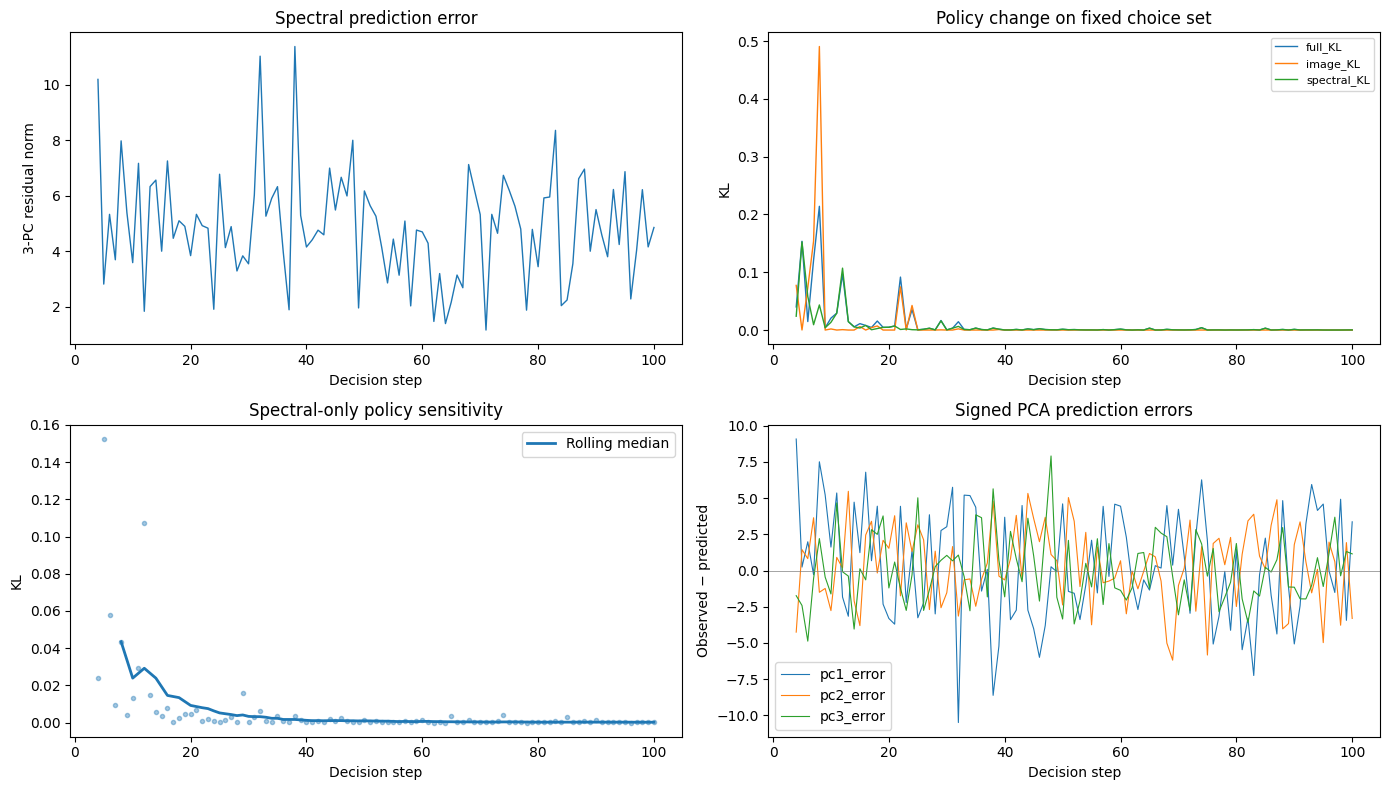

In [22]:
fig,ax=plt.subplots(2,2,figsize=(14,8))
ax[0,0].plot(D.step,D.surprise,lw=1);ax[0,0].set(title='Spectral prediction error',xlabel='Decision step',ylabel='3-PC residual norm')
for k in ['full_KL','image_KL','spectral_KL']:ax[0,1].plot(D.step,D[k],label=k,lw=1)
ax[0,1].legend(fontsize=8);ax[0,1].set(title='Policy change on fixed choice set',xlabel='Decision step',ylabel='KL')
ax[1,0].scatter(D.step,D.spectral_KL,s=9,alpha=.4)
ax[1,0].plot(D.step,D.spectral_KL.rolling(ROLLING,min_periods=5).median(),label='Rolling median',lw=2)
ax[1,0].legend();ax[1,0].set(title='Spectral-only policy sensitivity',xlabel='Decision step',ylabel='KL')
for k in ['pc1_error','pc2_error','pc3_error']:ax[1,1].plot(D.step,D[k],label=k,lw=.8)
ax[1,1].legend();ax[1,1].axhline(0,color='gray',lw=.5)
ax[1,1].set(title='Signed PCA prediction errors',xlabel='Decision step',ylabel='Observed − predicted')
plt.tight_layout();plt.savefig(os.path.join(DIAG_DIR,'time_series.png'),dpi=160);plt.show()

## 2. Decision-state diagrams and correlation

Compare the same spectral prediction error against **full KL**, **spectral-only KL**, and RMS spectral-feature change over the reference patches. Point color is decision step. Spearman rank correlations are reported with and without the first ridge-activation event. The sequential observations are dependent, so these correlations are descriptive, not independent-sample significance tests.

A large prediction error and small spectral-only KL means the fitted predictor was surprised, but its updated spectral features hardly altered the choice probabilities on the reference set. This does not prove the human ignored the spectrum.

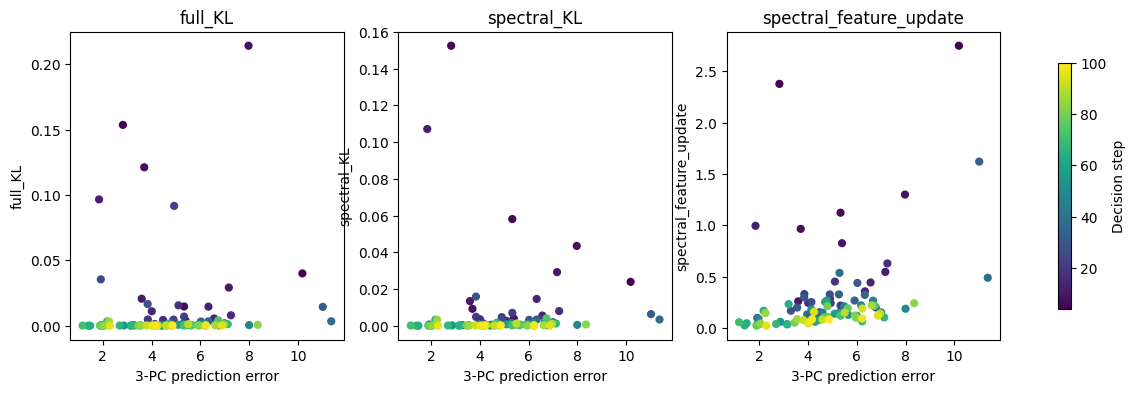

All N= 97
  full_KL Spearman rho= 0.333
  spectral_KL Spearman rho= 0.383
  spectral_feature_update Spearman rho= 0.465
Excluding ridge activation N= 96
  full_KL Spearman rho= 0.316
  spectral_KL Spearman rho= 0.366
  spectral_feature_update Spearman rho= 0.448


In [23]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
for a,k in zip(ax,['full_KL','spectral_KL','spectral_feature_update']):
    sc=a.scatter(D.surprise,D[k],c=D.step,cmap='viridis',s=24)
    a.set(xlabel='3-PC prediction error',ylabel=k,title=k)
fig.colorbar(sc,ax=ax.tolist(),label='Decision step',shrink=.8)
fig.savefig(os.path.join(DIAG_DIR,'decision_state.png'),dpi=160,bbox_inches='tight');plt.show()
for label,df in [('All',D),('Excluding ridge activation',D[D.ridge_activation==0])]:
    print(label,'N=',len(df))
    for k in ['full_KL','spectral_KL','spectral_feature_update']:
        print(' ',k,'Spearman rho=',round(spearmanr(df.surprise,df[k]).statistic,3))

## 3. Contrast influential and uninformative surprises

We choose two non-overlapping groups: the five observations with the largest **spectral-only** policy KL; and five of the 20 most surprising remaining observations with the **smallest** spectral-only KL. These are model-selected examples, not independent validation. The annotated scatterplot and table identify the corresponding decision steps, PC residuals, and policy changes.

,group,step,surprise,spectral_KL,full_KL,pc1_error,pc2_error,pc3_error
0,Large policy update,5,2.82362,0.15246,0.15357,0.23821,1.44219,-2.41581
1,Large policy update,12,1.84516,0.10711,0.09659,-1.83501,0.17248,-0.08729
2,Large policy update,6,5.33186,0.05808,0.01470,1.98554,0.82148,-4.87971
3,Large policy update,8,7.97370,0.04346,0.21410,7.51305,-1.50521,2.20641
4,Large policy update,11,7.16631,0.02919,0.02919,5.35710,0.90713,4.67275
5,"Surprising, small update",95,6.86608,0.00004,0.00004,4.59243,-4.98316,-1.10490
6,"Surprising, small update",98,6.21901,0.00005,0.00005,4.92407,-3.78089,-0.36668
7,"Surprising, small update",75,6.20216,0.00005,0.00005,2.04980,-5.84078,-0.38792
8,"Surprising, small update",93,6.22563,0.00022,0.00022,5.94287,-1.54279,-1.02986
9,"Surprising, small update",87,6.61256,0.00030,0.00030,-4.38674,4.89192,0.74268


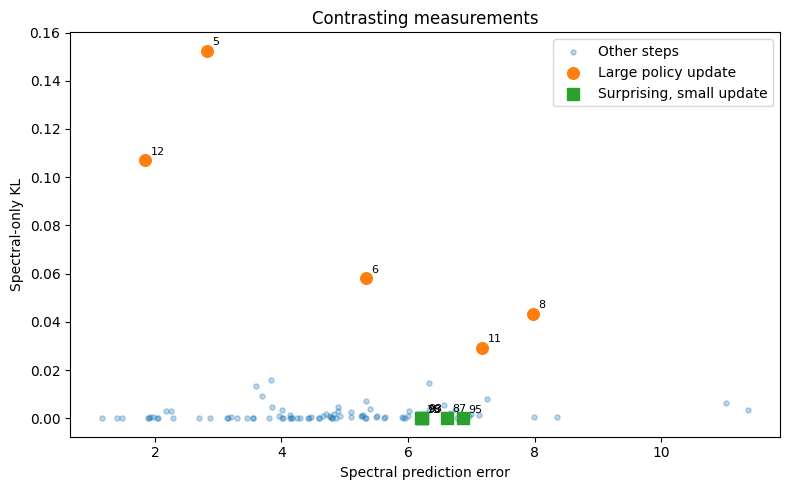

In [24]:
eligible=D[D.ridge_activation==0].copy()
A=eligible.nlargest(TOP_N,'spectral_KL').assign(group='Large policy update')
rest=eligible.drop(index=A.index)
B=rest.nlargest(min(len(rest),4*TOP_N),'surprise').nsmallest(TOP_N,'spectral_KL').assign(group='Surprising, small update')
EVENTS=pd.concat([A,B],ignore_index=True)
display(EVENTS[['group','step','surprise','spectral_KL','full_KL','pc1_error','pc2_error','pc3_error']].round(5))
EVENTS.to_csv(os.path.join(DIAG_DIR,'selected_events.csv'),index=False)
fig,ax=plt.subplots(figsize=(8,5));ax.scatter(eligible.surprise,eligible.spectral_KL,s=14,alpha=.3,label='Other steps')
for name,mark in [('Large policy update','o'),('Surprising, small update','s')]:
    sub=EVENTS[EVENTS.group==name];ax.scatter(sub.surprise,sub.spectral_KL,s=70,marker=mark,label=name)
    for _,r in sub.iterrows():ax.annotate(str(int(r.step)),(r.surprise,r.spectral_KL),xytext=(4,4),textcoords='offset points',fontsize=8)
ax.set(xlabel='Spectral prediction error',ylabel='Spectral-only KL',title='Contrasting measurements');ax.legend()
plt.tight_layout();plt.savefig(os.path.join(DIAG_DIR,'contrasting_events.png'),dpi=160);plt.show()

## 4. Inspect the selected patches and measured spectra

For each event, show the chosen image patch, its **observed and pre-measurement predicted** three spectral PCA coefficients, and the original measured EELS spectrum. The predicted PCs are obtained from the ridge model trained on strictly earlier measurements; the current spectrum never enters its own prediction. This makes it possible to ask whether influential updates correspond to particular image morphologies or physical EELS features. PCA components are statistical coordinates; interpret their physical meaning using the PCA loadings above.

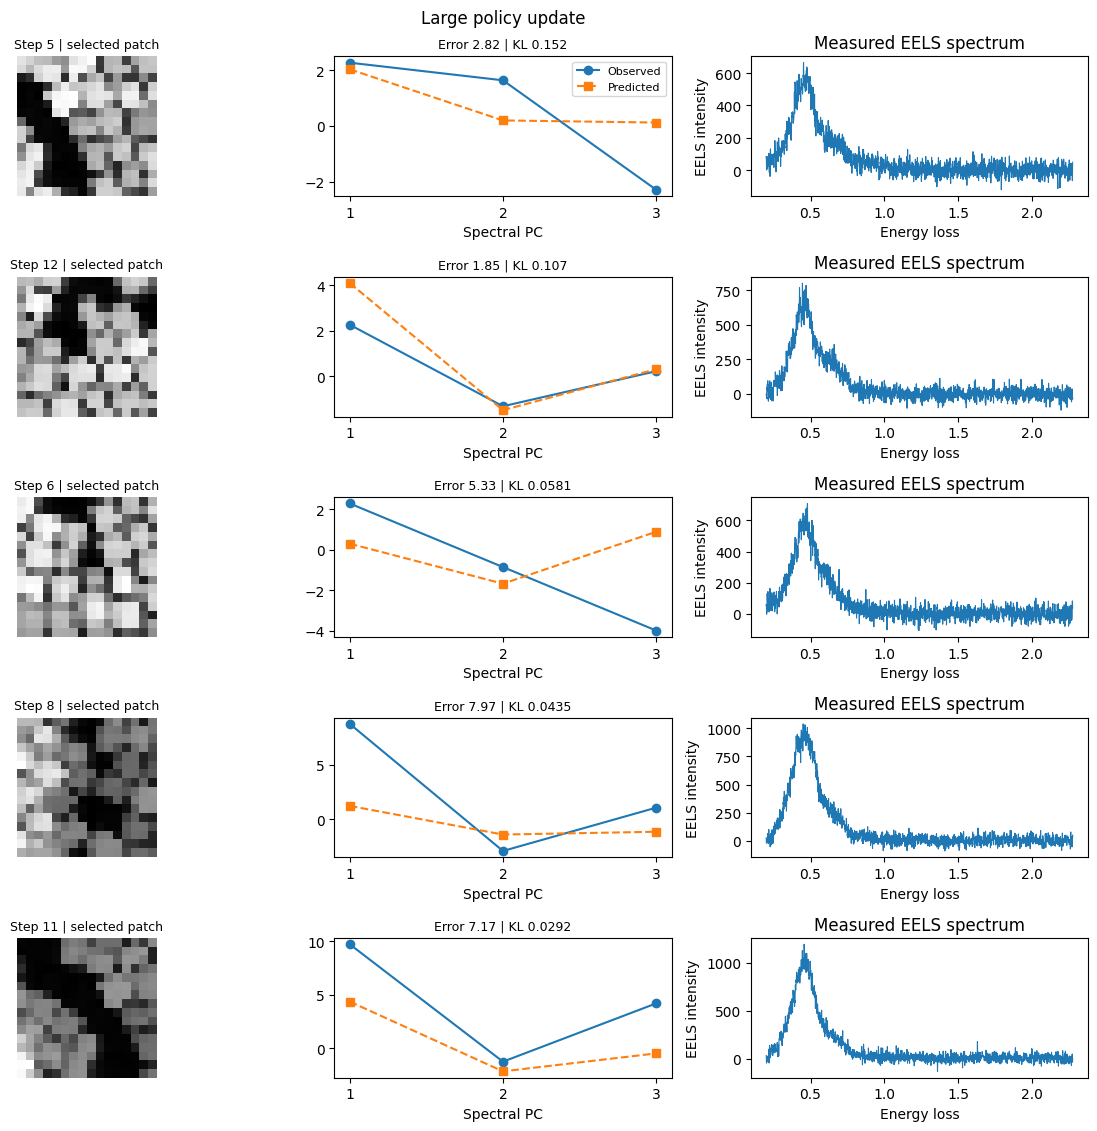

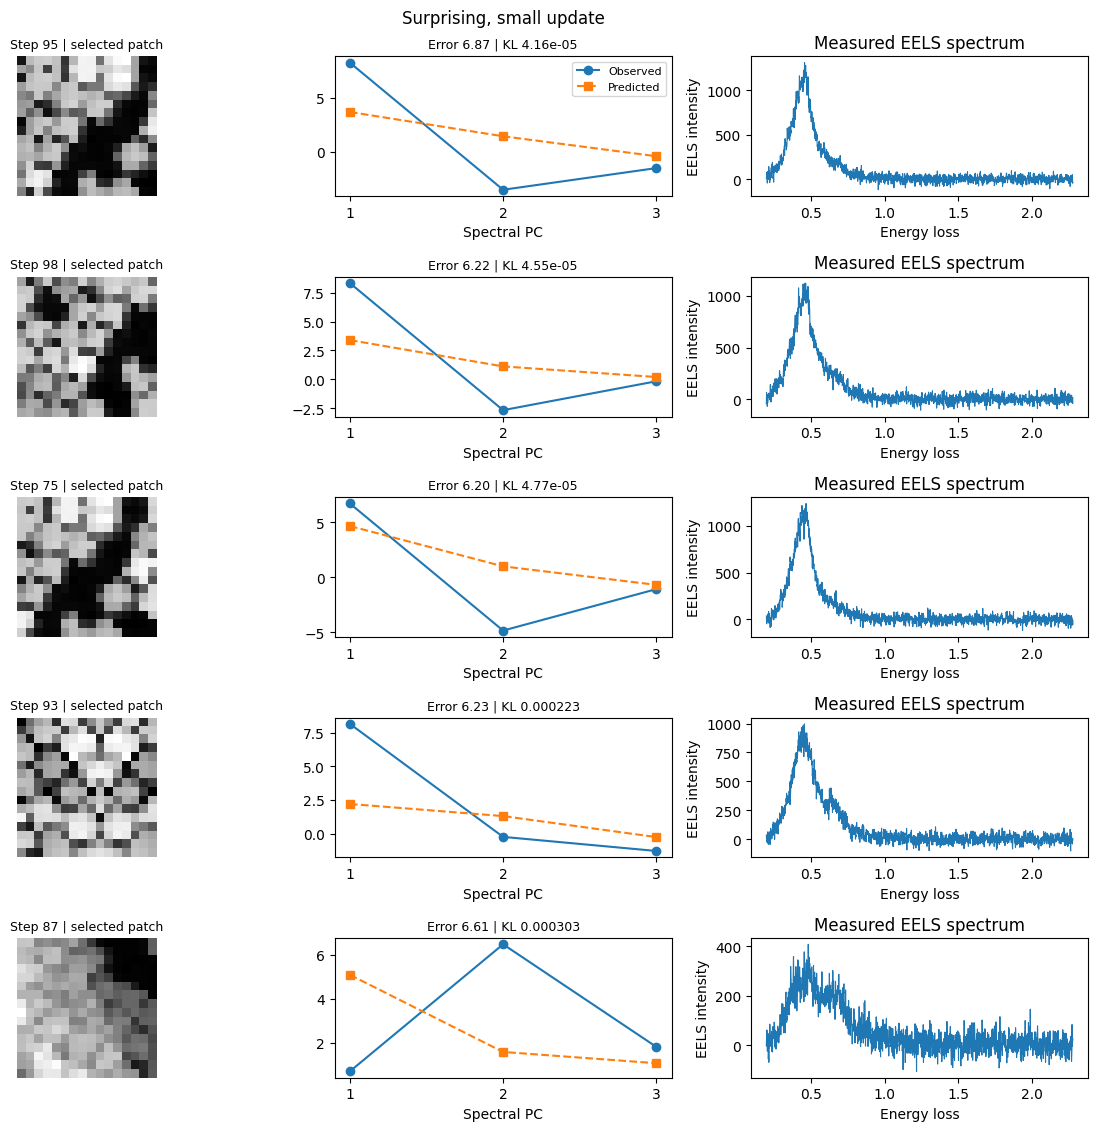

In [25]:
for group,sub in EVENTS.groupby('group',sort=False):
    fig,axes=plt.subplots(len(sub),3,figsize=(12,2.3*len(sub)),squeeze=False)
    for row,(_,event) in enumerate(sub.iterrows()):
        t=int(event['index']);d=trace[t]
        patch=patch2d(d['candidate_patches'][chosen[t]])
        axes[row,0].imshow(patch,cmap='gray');axes[row,0].axis('off');axes[row,0].set_title(f'Step {t+1} | selected patch',fontsize=9)
        pred=belief(t).predict(ox[t:t+1])[0];pcs=np.arange(1,len(pred)+1)
        axes[row,1].plot(pcs,oy[t],'o-',label='Observed');axes[row,1].plot(pcs,pred,'s--',label='Predicted')
        axes[row,1].set_xticks(pcs);axes[row,1].set_xlabel('Spectral PC');axes[row,1].set_title(f'Error {event.surprise:.2f} | KL {event.spectral_KL:.3g}',fontsize=9)
        if row==0:axes[row,1].legend(fontsize=8)
        raw=np.asarray(d['selected_spectrum']).ravel();axis=np.asarray(d['selected_axis']).ravel()
        if len(axis)!=len(raw):axis=np.arange(len(raw))
        axes[row,2].plot(axis,raw,lw=.8);axes[row,2].set(xlabel='Energy loss',ylabel='EELS intensity',title='Measured EELS spectrum')
    fig.suptitle(group);plt.tight_layout()
    fn='large_updates' if group=='Large policy update' else 'surprising_stable'
    plt.savefig(os.path.join(DIAG_DIR,fn+'_spectra.png'),dpi=150);plt.show()

## 5. Before/after maps for the largest spectral updates

For the three most influential events, we evaluate M2 on **every grid location** in three states: **before**, **image selected but spectrum withheld**, and **image and spectrum incorporated**. The fourth map shows `full post − image-only post`, which is the **incremental spectral-only utility update** with image history held fixed. The first three maps share one centered color scale. The difference map uses a separate symmetric scale. These are fitted-model counterfactual calculations, not observed human responses or actual spectra at unselected locations. Spatial reliability depends on the patch reconstruction check above.

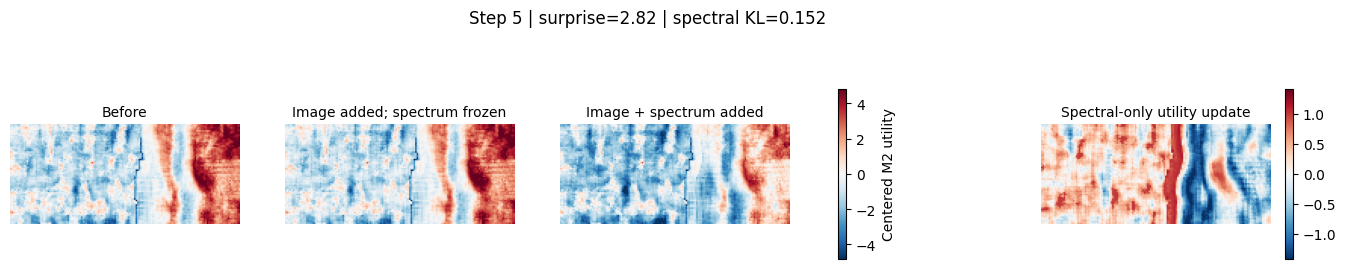

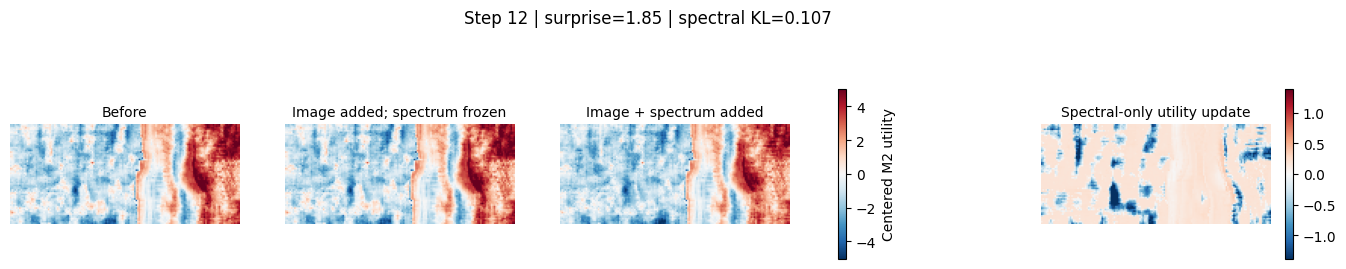

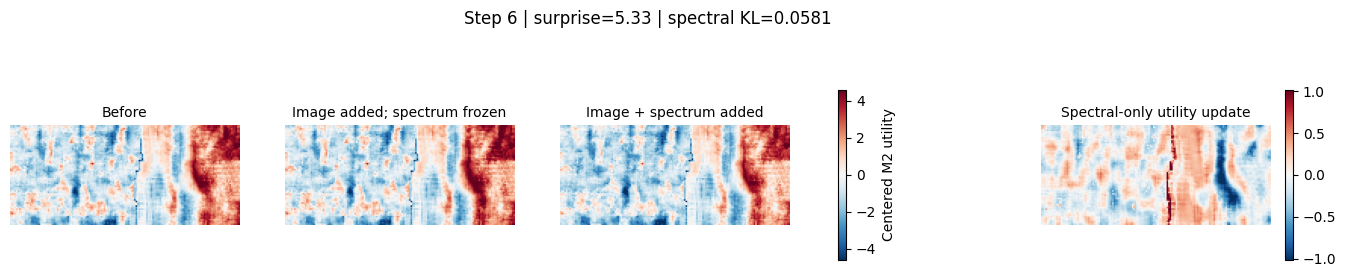

In [26]:
for _,event in A.head(3).iterrows():
    t=int(event['index']);q=grid_x
    before=utility(q,t,t).reshape(H,W)
    imagepost=utility(q,t+1,t).reshape(H,W)
    full=utility(q,t+1,t+1).reshape(H,W)
    diff=full-imagepost
    center=before.mean();lim=max(np.percentile(np.abs(np.concatenate([(z-center).ravel() for z in [before,imagepost,full]])),99),1e-8)
    dlim=max(np.percentile(np.abs(diff-diff.mean()),99),1e-8)
    fig,axes=plt.subplots(1,4,figsize=(17,3.4))
    for a,z,title in zip(axes[:3],[before,imagepost,full],['Before','Image added; spectrum frozen','Image + spectrum added']):
        im=a.imshow(z-center,cmap='RdBu_r',vmin=-lim,vmax=lim);a.set_title(title,fontsize=10);a.axis('off')
    fig.colorbar(im,ax=axes[:3].tolist(),shrink=.65,label='Centered M2 utility')
    im2=axes[3].imshow(diff-diff.mean(),cmap='RdBu_r',vmin=-dlim,vmax=dlim)
    axes[3].set_title('Spectral-only utility update',fontsize=10);axes[3].axis('off')
    fig.colorbar(im2,ax=axes[3],shrink=.65)
    fig.suptitle(f'Step {t+1} | surprise={event.surprise:.2f} | spectral KL={event.spectral_KL:.3g}')
    plt.savefig(os.path.join(DIAG_DIR,f'spatial_update_step_{t+1}.png'),dpi=150,bbox_inches='tight');plt.show()

## 6. Reading the results, limits, and saved outputs

**Primary scientific test:** The earlier held-out **M2 versus M1 choice log-likelihood** remains the test of whether spectral history improves prediction. Large spectral utility maps or KL updates alone cannot establish this.

**How to interpret these diagnostics:**

- **Surprise vs spectral KL:** Does a difficult-to-predict spectrum actually change the *decision-relevant* features of the fitted model?
- **Full KL vs spectral KL:** Are changes mainly caused by adding the selected image to history, or by updating the spectral predictor?
- **PC residuals:** Is surprise concentrated in PCs that the utility model does not strongly use?
- **Contrasting event spectra:** Do large policy updates correspond to recognizable spectral features or distinctive morphologies?
- **Before/after maps:** Where on the image would the fitted policy's utility increase or decrease after one observation?
- **Temporal trends:** Does the model become less sensitive with increasing history length?

**Limits:** We reconstruct a policy from recorded choices, not an observable human belief state. M2 uses ridge regression and two simple spectral-history features, not a calibrated Bayesian belief. KL is evaluated on a fixed first choice set, so changes elsewhere may be missed. PCA was fitted on other traces and can still contain sample-level information; avoid claims of generalization to new specimens. The original notebook's feature scaling and VAE training are exploratory rather than strictly nested for cross-trace inference. Event groups are selected after inspecting the model and cannot be treated as independent hypothesis tests. Full EELS spectra of unselected patches are not used.

**Saved files:** `events.csv`, `selected_events.csv`, `time_series.png`, `decision_state.png`, `contrasting_events.png`, two event-spectrum figures, and three before/after spatial-map figures in `day22_light_results/expanded_diagnostics/`.

**Suggested next step after running:** Examine whether M2 actually improves held-out log-likelihood over M1, then inspect the top event spectra. If the improvement is absent, interpret the spectral sensitivity maps as model behavior rather than evidence of spectroscopic decision-making.

# Grade 9 — Compare **all decision traces** independently

The previous sections show a detailed example for one trace. This section evaluates **every loaded trace** with the same M0/M1/M2 modeling assumptions, rather than pooling fundamentally different policies.

- **M0** uses only current image descriptors (five hand-engineered features plus four optional VAE latents).
- **M1** adds one descriptor: the minimum distance to previously selected images in feature space.
- **M2** adds two descriptors computed using *previously observed spectra*: predicted spectral PC1 and predicted novelty relative to measured spectral PCA vectors.

For each trace, the image-to-spectrum ridge model is reconstructed chronologically: the current spectrum is not used to predict the current decision. Each trace has its own conditional-softmax weights. The first 70% of decisions train the choice model; the last 30% are held out. The choice-feature standardizer is fit only on the training period. During held-out evaluation the spectral model is updated after each actually observed test measurement (one-step-ahead, not an autonomous rollout).

**Scientific test:** Does M2 improve held-out selected-choice log-probability relative to M1? A larger training likelihood alone is not evidence. Random selection is a critical negative control. EI/UCB and P01/P03 should be analyzed separately; labels alone do not prove their policy identities.

**Scope and limitations:** Spectral PCA and VAE are shared unsupervised representations trained elsewhere in this notebook, potentially on all traces. This is a within-dataset/transductive comparison, not a claim of out-of-specimen generalization. A single trajectory per policy gives limited statistical power. Unselected spectra are not used in choice-model fitting.

In [27]:
from scipy.special import logsumexp, softmax
from scipy.optimize import minimize
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
COMPARE_DIR=os.path.join(RESULTS,'all_traces_comparison')
os.makedirs(COMPARE_DIR,exist_ok=True)
TRACE_LABELS={0:'EI',1:'Random',2:'UCB',3:'P01',4:'P03'}
TRACE_IDS=sorted(traces)

def build_trace(tid):
    ds=traces[tid]['decisions'];xx=[encode(d['candidate_patches']) for d in ds]
    yy=np.stack([ypc(d['selected_spectrum']) for d in ds]);aa=np.array([int(d['selected_position']) for d in ds])
    T=len(ds);K,dim=xx[0].shape
    if T<12 or any(z.shape!=(K,dim) for z in xx):raise ValueError(f'Trace {tid}: insufficient steps or inconsistent choice sets')
    histx=[];histy=[];rows=[];errors=np.full(T,np.nan)
    for t,(x,y,a) in enumerate(zip(xx,yy,aa)):
        if histx:
            hx=np.stack(histx);novel=np.linalg.norm(x[:,None,:]-hx[None,:,:],axis=2).min(axis=1)
        else:novel=np.zeros(K)
        sf=np.zeros((K,2))
        if len(histx)>=MIN_HISTORY:
            pred=Ridge(alpha=10).fit(np.stack(histx),np.stack(histy)).predict(x)
            sf[:,0]=pred[:,0]
            sf[:,1]=np.linalg.norm(pred[:,None,:]-np.stack(histy)[None,:,:],axis=2).min(axis=1)
            errors[t]=np.linalg.norm(pred[a]-y)
        rows.append(np.column_stack((x,novel,sf)))
        histx.append(x[a]);histy.append(y)
    raw=np.stack(rows);split=max(8,min(T-3,int(.7*T)))
    scale=StandardScaler().fit(raw[:split].reshape(-1,dim+3))
    scaled=scale.transform(raw.reshape(-1,dim+3)).reshape(T,K,dim+3)
    return dict(raw=raw,X=scaled,a=aa,split=split,K=K,dim=dim,scale=scale,
                chosenx=np.stack(histx),choseny=yy,errors=errors)

def fit_local(ds,model):
    dim=ds['dim']+{'M0':0,'M1':1,'M2':3}[model]
    z=ds['X'][:ds['split'],:,:dim];a=ds['a'][:ds['split']];N=len(a)
    def fun(w):
        u=z@w;p=softmax(u,axis=1)
        return ((logsumexp(u,axis=1)-u[np.arange(N),a]).sum()+.5*L2*(w@w),
                (p[:,:,None]*z).sum((0,1))-z[np.arange(N),a].sum(0)+L2*w)
    res=minimize(fun,np.zeros(dim),jac=True,method='L-BFGS-B',options={'maxiter':400})
    if not res.success:print('Optimizer:',res.message)
    return res.x

def evaluate_local(ds,w,part):
    z=ds['X'][:ds['split'],:,:len(w)] if part=='train' else ds['X'][ds['split']:,:,:len(w)]
    a=ds['a'][:ds['split']] if part=='train' else ds['a'][ds['split']:]
    u=z@w;lp=u-logsumexp(u,axis=1,keepdims=True)
    return float(lp[np.arange(len(a)),a].mean()),float(np.mean(np.argmax(u,axis=1)==a)),lp[np.arange(len(a)),a]

ALL_DATA={tid:build_trace(tid) for tid in TRACE_IDS}
ALL_WEIGHTS={};rows=[];per_step=[]
for tid,ds in ALL_DATA.items():
    ALL_WEIGHTS[tid]={}
    for model in ['M0','M1','M2']:
        w=fit_local(ds,model);ALL_WEIGHTS[tid][model]=w
        tr=evaluate_local(ds,w,'train');te=evaluate_local(ds,w,'test')
        rows.append(dict(trace=TRACE_LABELS.get(tid,str(tid)),trace_id=tid,model=model,
                         n_train=ds['split'],n_test=len(ds['a'])-ds['split'],
                         train_logp=tr[0],test_logp=te[0],test_top1=te[1],
                         improvement_over_random=te[0]+np.log(ds['K'])))
        for j,lp in enumerate(te[2]):per_step.append(dict(trace_id=tid,model=model,step=ds['split']+j+1,logp=lp))
ALL_RESULTS=pd.DataFrame(rows)
ALL_STEPS=pd.DataFrame(per_step)
ALL_RESULTS.to_csv(os.path.join(COMPARE_DIR,'all_trace_metrics.csv'),index=False)
ALL_STEPS.to_csv(os.path.join(COMPARE_DIR,'heldout_decision_logp.csv'),index=False)
display(ALL_RESULTS.round(4))


,trace,trace_id,model,n_train,n_test,train_logp,test_logp,test_top1,improvement_over_random
0,EI,0,M0,140,60,-2.4853,-2.5487,0.2667,0.4470
1,EI,0,M1,140,60,-2.3794,-2.4499,0.3000,0.5459
2,EI,0,M2,140,60,-2.3098,-2.5090,0.3333,0.4867
3,Random,1,M0,140,60,-2.9612,-3.0421,0.0500,-0.0463
4,Random,1,M1,140,60,-2.9612,-3.0414,0.0500,-0.0456
5,Random,1,M2,140,60,-2.9548,-3.0464,0.0500,-0.0507
6,UCB,2,M0,140,60,-2.6792,-2.3965,0.4000,0.5993
7,UCB,2,M1,140,60,-2.5737,-2.2032,0.4167,0.7925
8,UCB,2,M2,140,60,-2.5542,-2.1471,0.4167,0.8486
9,P01,3,M0,70,30,-2.2338,-2.5253,0.0667,0.4704


## 9.1 Comparative predictive performance

The first chart shows **held-out log-probability relative to uniform random choice**, so zero represents chance-level probabilistic prediction. The second shows held-out top-1 accuracy, with a 5% chance reference for 20 candidates.

The most important figure is the **incremental value of history**: $L(M1)-L(M0)$ isolates the predictive contribution of image-selection history, while $L(M2)-L(M1)$ isolates the additional contribution of spectral-history descriptors, *within the specified model family*. A negative increment indicates that the more complex model does not generalize better. All models are fitted separately for each trace.

These are descriptive held-out comparisons, not causal tests or evidence that a particular agent consciously anticipates spectra.

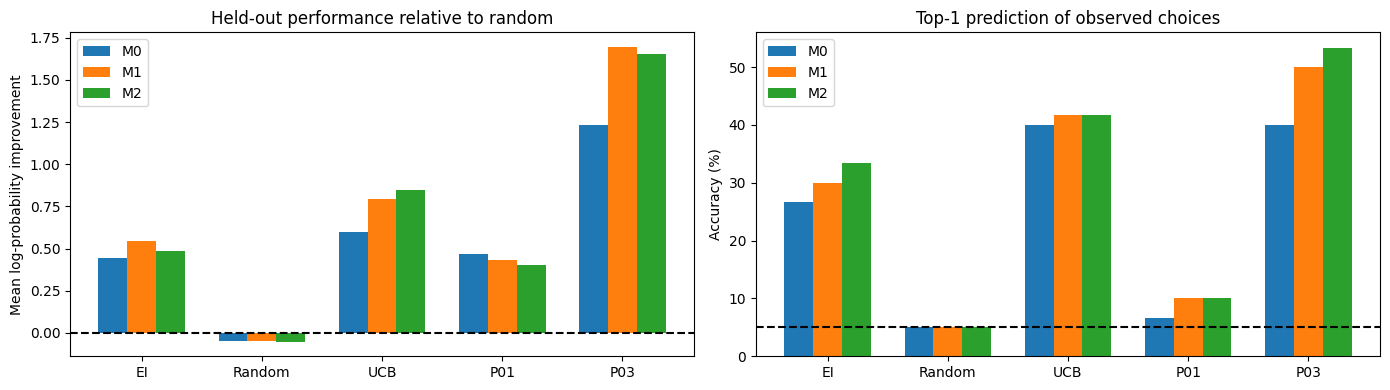

,trace,M1_minus_M0,M2_minus_M1
0,EI,0.09884,-0.05917
1,Random,0.00072,-0.00507
2,UCB,0.19326,0.05607
3,P01,-0.03801,-0.02696
4,P03,0.46098,-0.04012


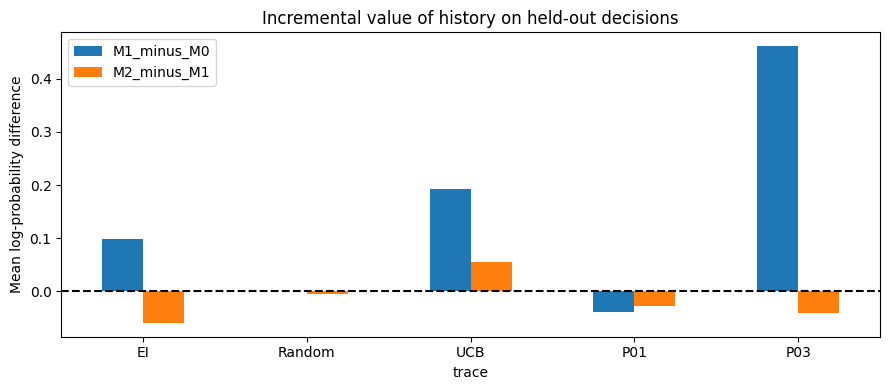

In [28]:
labels=[TRACE_LABELS.get(tid,str(tid)) for tid in TRACE_IDS]
models=['M0','M1','M2'];xx=np.arange(len(TRACE_IDS));width=.24
fig,ax=plt.subplots(1,2,figsize=(14,4))
for k,model in enumerate(models):
    subset=ALL_RESULTS[ALL_RESULTS.model==model].set_index('trace_id')
    ax[0].bar(xx+(k-1)*width,[subset.loc[tid,'improvement_over_random'] for tid in TRACE_IDS],width,label=model)
    ax[1].bar(xx+(k-1)*width,[100*subset.loc[tid,'test_top1'] for tid in TRACE_IDS],width,label=model)
ax[0].axhline(0,c='black',ls='--');ax[0].set(title='Held-out performance relative to random',ylabel='Mean log-probability improvement')
ax[1].axhline(5,c='black',ls='--');ax[1].set(title='Top-1 prediction of observed choices',ylabel='Accuracy (%)')
for a in ax:a.set_xticks(xx,labels);a.legend()
plt.tight_layout();plt.savefig(os.path.join(COMPARE_DIR,'all_trace_performance.png'),dpi=150);plt.show()
piv=ALL_RESULTS.pivot(index='trace_id',columns='model',values='test_logp').loc[TRACE_IDS]
DELTAS=pd.DataFrame({'trace':labels,'M1_minus_M0':(piv.M1-piv.M0).values,'M2_minus_M1':(piv.M2-piv.M1).values})
display(DELTAS.round(5));DELTAS.to_csv(os.path.join(COMPARE_DIR,'incremental_value.csv'),index=False)
fig,ax=plt.subplots(figsize=(9,4));DELTAS.set_index('trace')[['M1_minus_M0','M2_minus_M1']].plot.bar(ax=ax,rot=0)
ax.axhline(0,c='black',ls='--');ax.set(title='Incremental value of history on held-out decisions',ylabel='Mean log-probability difference')
plt.tight_layout();plt.savefig(os.path.join(COMPARE_DIR,'incremental_value.png'),dpi=150);plt.show()


## 9.2 Compare inferred preference maps across policies

We evaluate the independently fitted M0, M1, and M2 models on the **same complete spatial grid** at each trace's final knowledge state. The final panel is the explicit spectral-history term within M2. This is different from subtracting independently fitted M2 and M1 utilities: their visual coefficients can also differ.

Each map is centered to remove the arbitrary additive utility offset. For comparison, each column uses a shared symmetric color range across traces. These maps show **modeled selection utilities**, not ground-truth physical rewards. Spatial coordinates are used only for visualization, not as model inputs. All maps use the same precomputed grid image descriptors from the earlier section.

The random-policy map is a negative control: any pronounced patterns inferred there are a warning about overfitting or descriptor correlations. Do not infer policy mechanisms from map appearance alone; interpret alongside held-out choice likelihood.

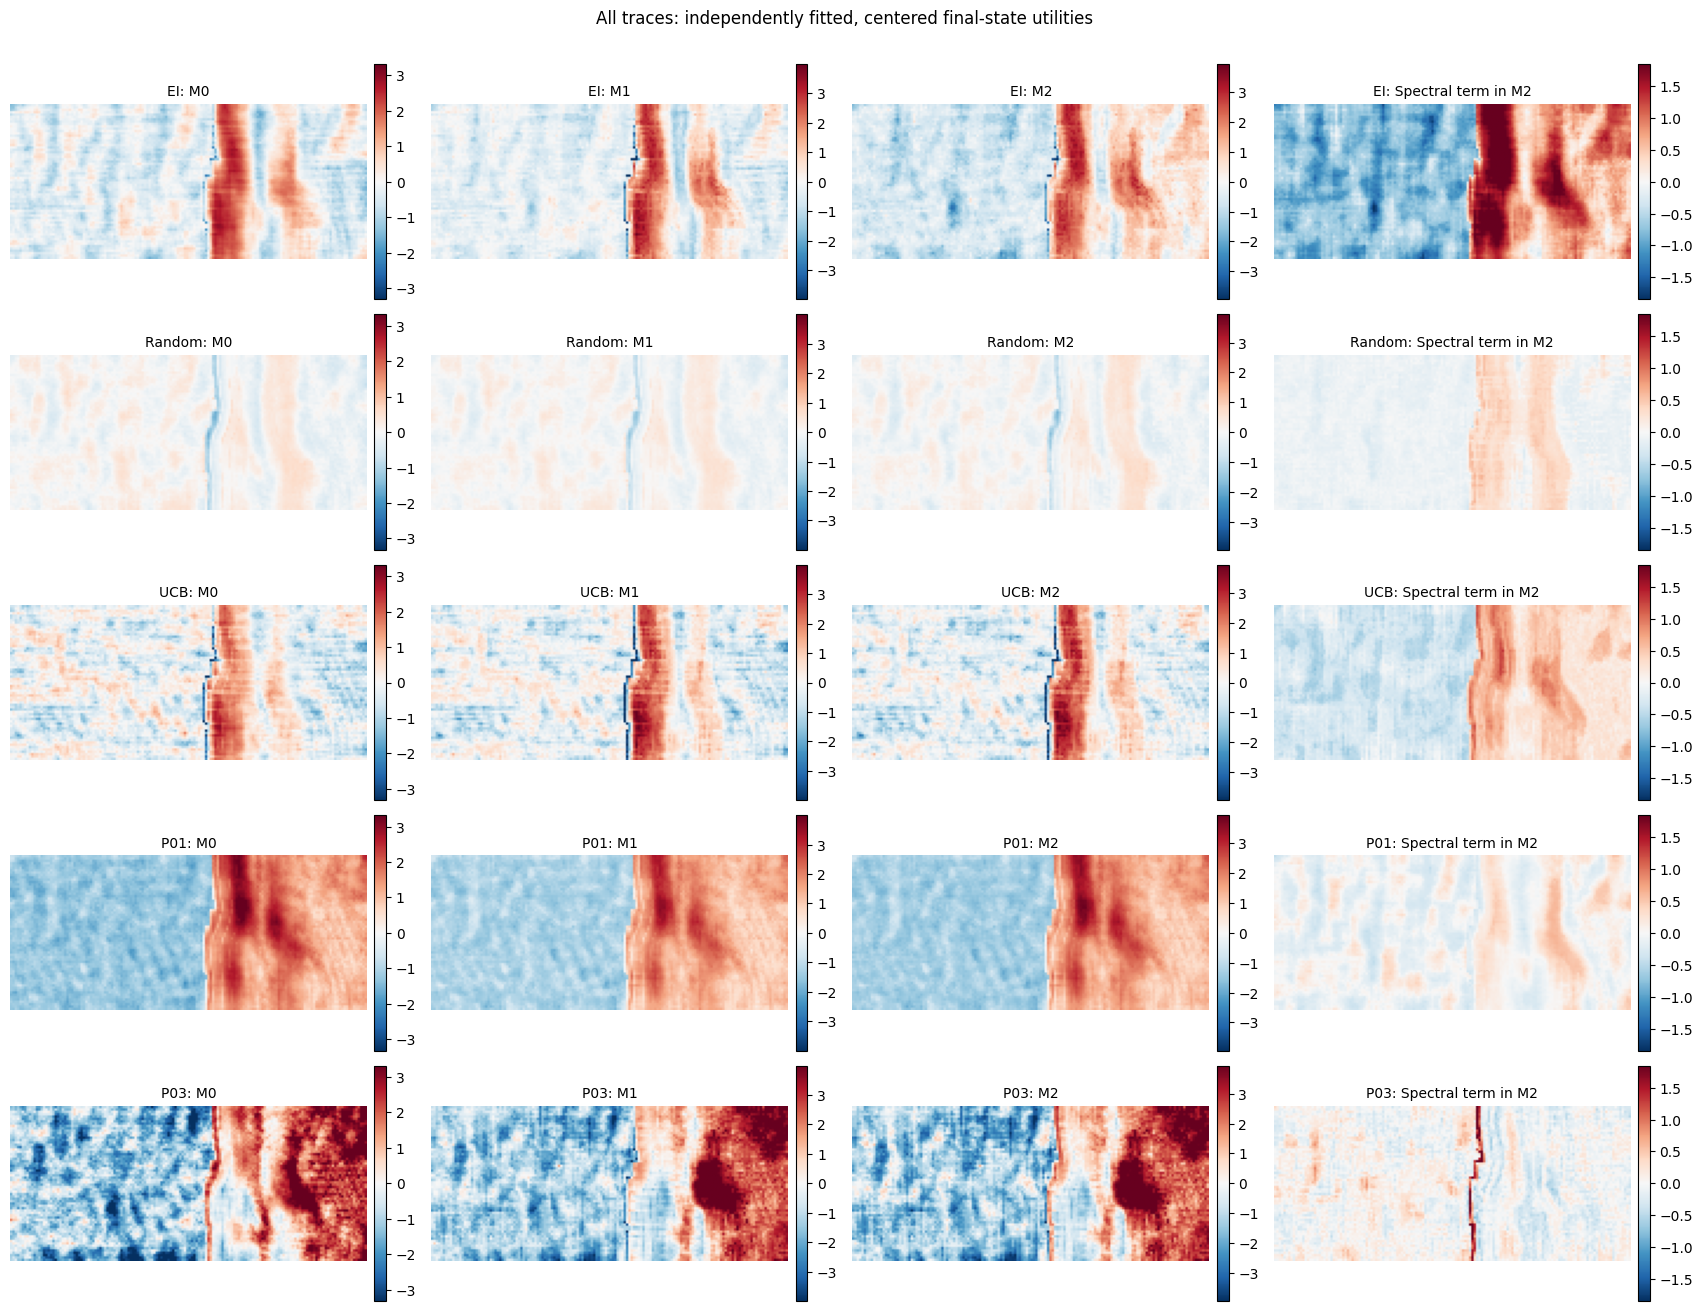

In [29]:
def final_trace_maps(tid):
    ds=ALL_DATA[tid];t=len(ds['a']);hx=ds['chosenx'];hy=ds['choseny'];q=grid_x
    novelty=np.empty(len(q))
    for j in range(0,len(q),512):
        novelty[j:j+512]=np.linalg.norm(q[j:j+512,None,:]-hx[None,:,:],axis=2).min(axis=1)
    sf=np.zeros((len(q),2))
    if t>=MIN_HISTORY:
        pred=Ridge(alpha=10).fit(hx,hy).predict(q)
        sf[:,0]=pred[:,0]
        for j in range(0,len(q),512):
            sf[j:j+512,1]=np.linalg.norm(pred[j:j+512,None,:]-hy[None,:,:],axis=2).min(axis=1)
    z=ds['scale'].transform(np.column_stack([q,novelty,sf]));d=ds['dim']
    v0=z[:,:d]@ALL_WEIGHTS[tid]['M0']
    v1=z[:,:d+1]@ALL_WEIGHTS[tid]['M1']
    w=ALL_WEIGHTS[tid]['M2'];v2=z@w
    vs=z[:,d+1:]@w[d+1:]
    return {name:(v-v.mean()).reshape(H,W) for name,v in [('M0',v0),('M1',v1),('M2',v2),('Spectral term in M2',vs)]}

MAPS={tid:final_trace_maps(tid) for tid in TRACE_IDS}
keys=['M0','M1','M2','Spectral term in M2']
limits={k:max(1e-8,np.percentile(np.abs(np.concatenate([MAPS[t][k].ravel() for t in TRACE_IDS])),99)) for k in keys}
fig,axes=plt.subplots(len(TRACE_IDS),4,figsize=(17,2.6*len(TRACE_IDS)),squeeze=False)
for row,tid in enumerate(TRACE_IDS):
    for col,key in enumerate(keys):
        z=MAPS[tid][key];lim=limits[key]
        im=axes[row,col].imshow(z,cmap='RdBu_r',vmin=-lim,vmax=lim)
        axes[row,col].set_title(f'{TRACE_LABELS.get(tid,str(tid))}: {key}',fontsize=10)
        axes[row,col].axis('off')
        fig.colorbar(im,ax=axes[row,col],fraction=.035,pad=.02)
plt.suptitle('All traces: independently fitted, centered final-state utilities',y=1.005)
plt.tight_layout();plt.savefig(os.path.join(COMPARE_DIR,'all_trace_utility_atlas.png'),dpi=150,bbox_inches='tight');plt.show()


## 9.3 Final interpretation checklist

1. **Negative control:** Do M0–M2 stay near random on the random trace? If not, investigate overfitting, trace provenance, and train/test shifts.
2. **Visual preference:** Does M0 exceed random on P01/P03, EI, or UCB? If yes, the current image descriptors contain predictive information.
3. **Image memory:** Is $L(M1)-L(M0)$ consistently positive? If not, morphological novelty as currently encoded adds little predictive information.
4. **Spectral feedback:** Is $L(M2)-L(M1)$ positive and reproducible on a nonrandom trace? If yes, observed spectral history improves predictive reconstruction under this model.
5. **Map interpretation:** A large or attractive spectral utility map alone is insufficient. Verify that the corresponding model improves held-out predictions.
6. **No objective switching:** The comparison assumes one fixed fitted choice rule per trace. It does not test switching scientific goals or causal effects.

**Next experimental improvement:** Collect multiple independent trajectories from each generating policy, and, if possible, repeat on additional spectral images. This will permit policy-specific uncertainty intervals and genuine out-of-specimen validation.

All comparison tables and figures are saved to `day22_light_results/all_traces_comparison/`. The original data-loading cells remain unchanged.